# Big Data 4.0.3 - stabilne analizy MongoDB - rynek Uber i Lyft w Nowym Jorku (VII-VIII 2026)

**Pytanie badawcze:** jak zmienia się rynek przejazdów high-volume FHV (Uber/Lyft) w NYC, jaki wpływ mają pora dnia, przewoźnik i trasa na opłatę, oczekiwanie, tempo jazdy i napiwki? Czy możemy utrzymywać spójny katalog dostępności danych TLC i zsynchronizować zagregowane wyniki pomiędzy lokalnym MongoDB a darmowym MongoDB Atlas?

**Źródła:**
- NYC TLC Trip Record Data: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- HVFHV Parquet: https://d37ci6vzurychx.cloudfront.net/trip-data/
- Taxi Zones: https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv
- MongoDB Atlas Free limits: https://www.mongodb.com/docs/atlas/reference/free-shared-limitations/

**Oryginalne dane:** `fhvhv_tripdata_2026-07.parquet` i `fhvhv_tripdata_2026-08.parquet`, 41,4 mln wierszy według zapisanych wyników źródłowego notebooka. **Rozmiar pliku Parquet po kompresji ≠ wielkość danych nieskompresowanych ani rozmiar BSON.** Wielkości weryfikujemy liczbowo niżej.

In [1]:
from pathlib import Path
import os
from dotenv import load_dotenv
load_dotenv(".env")
import time
import urllib.request

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from bson import BSON
from pymongo import MongoClient, ASCENDING

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
MONTHS = ["2026-07", "2026-08"]
TLC_BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data"
SOURCE_FILES = [DATA_DIR / f"fhvhv_tripdata_{m}.parquet" for m in MONTHS]
MERGED_FILE = DATA_DIR / "fhvhv_tripdata_2026-07_08.parquet"
ZONES_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
ZONES_FILE = DATA_DIR / "taxi_zone_lookup.csv"

MONGO_URI = os.getenv("LOCAL_MONGO_URI", "mongodb://localhost:27017")
DB_NAME = "nyc_taxi"
TRIPS = "fhvhv_trips"
QUALITY = "import_quality"

TARGET_DATA_GB = 5.5
REIMPORT = False
BATCH_ROWS = 250_000
INSERT_CHUNK = 5_000
RANDOM_SEED = 42

PERIOD_START = pd.Timestamp("2026-07-01")
PERIOD_END = pd.Timestamp("2026-09-01")
GIB = 1024 ** 3

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PROVIDER_COLORS = {"Uber": SERIES[0], "Lyft": SERIES[1], "Via": SERIES[2], "Juno": SERIES[3]}
MONTH_COLORS = {"2026-07": SERIES[0], "2026-08": SERIES[1]}
BLUES = sns.blend_palette(["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"], as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#b5b4ae", "grid.color": "#e6e5e0", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.dpi": 110,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 50)

## 1. Pobranie danych i połączenie plików miesięcznych w jeden plik Parquet

In [2]:
def download_file(url, target, chunk_size=8 * 1024 * 1024):
    part = target.with_suffix(target.suffix + ".part")
    t0 = time.time()
    with urllib.request.urlopen(url) as response, open(part, "wb") as out:
        total = int(response.headers.get("Content-Length", 0))
        done, next_report = 0, 0.1
        while chunk := response.read(chunk_size):
            out.write(chunk)
            done += len(chunk)
            if total and done / total >= next_report:
                print(f"  {target.name}: {done / total:4.0%} ({done / 1024**2:,.0f} MiB)")
                next_report += 0.1
    if total and part.stat().st_size != total:
        part.unlink()
        raise IOError(f"Niepełne pobranie {url}: {done} z {total} bajtów")
    part.replace(target)
    print(f"Pobrano {target.name} ({target.stat().st_size / 1024**2:,.0f} MiB) w {time.time() - t0:.0f} s")


def merge_parquet(sources, target):
    schema = pq.ParquetFile(sources[0]).schema_arrow
    for src in sources[1:]:
        other = pq.ParquetFile(src).schema_arrow
        if not other.equals(schema):
            print(f"Uwaga: schemat {src.name} różni się od {sources[0].name} - kolumny zostaną rzutowane.")
    tmp = target.with_suffix(".parquet.tmp")
    t0 = time.time()
    with pq.ParquetWriter(tmp, schema, compression="zstd") as writer:
        for src in sources:
            pf = pq.ParquetFile(src)
            for i in range(pf.num_row_groups):
                writer.write_table(pf.read_row_group(i).select(schema.names).cast(schema))
            print(f"  dopisano {src.name}: {pf.metadata.num_rows:,} wierszy")
    tmp.replace(target)
    print(f"Zapisano {target.name} w {time.time() - t0:.0f} s")


if MERGED_FILE.exists():
    print(f"Plik {MERGED_FILE.name} już istnieje - pomijam scalanie.")
else:
    for month, path in zip(MONTHS, SOURCE_FILES):
        if path.exists():
            print(f"Plik {path.name} już jest na dysku - pomijam pobieranie.")
        else:
            download_file(f"{TLC_BASE_URL}/{path.name}", path)
    merge_parquet(SOURCE_FILES, MERGED_FILE)

merged = pq.ParquetFile(MERGED_FILE)
source_rows = {f.name: pq.ParquetFile(f).metadata.num_rows for f in SOURCE_FILES if f.exists()}
print(f"Scalony plik: {merged.metadata.num_rows:,} wierszy, {merged.num_row_groups} grup wierszy, "
      f"{MERGED_FILE.stat().st_size / GIB:.2f} GiB")
if source_rows:
    assert merged.metadata.num_rows == sum(source_rows.values()), "Liczba wierszy nie zgadza się ze źródłami!"
    print("Kontrola: liczba wierszy = suma plików źródłowych", source_rows)

Plik fhvhv_tripdata_2026-07_08.parquet już istnieje - pomijam scalanie.
Scalony plik: 41,414,729 wierszy, 40 grup wierszy, 0.93 GiB
Kontrola: liczba wierszy = suma plików źródłowych {'fhvhv_tripdata_2026-07.parquet': 20921249, 'fhvhv_tripdata_2026-08.parquet': 20493480}


## 2. Przegląd surowych danych

In [3]:
print(merged.schema_arrow)
merged.read_row_group(0).slice(0, 5).to_pandas().T

hvfhs_license_num: large_string
dispatching_base_num: large_string
originating_base_num: large_string
request_datetime: timestamp[us]
on_scene_datetime: timestamp[us]
pickup_datetime: timestamp[us]
dropoff_datetime: timestamp[us]
PULocationID: int32
DOLocationID: int32
trip_miles: double
trip_time: int64
base_passenger_fare: double
tolls: double
bcf: double
sales_tax: double
congestion_surcharge: double
airport_fee: double
tips: double
driver_pay: double
shared_request_flag: large_string
shared_match_flag: large_string
access_a_ride_flag: large_string
wav_request_flag: large_string
wav_match_flag: large_string
cbd_congestion_fee: double


,0,1,2,3,4
hvfhs_license_num,HV0003,HV0003,HV0003,HV0005,HV0005
dispatching_base_num,B03404,B03404,B03404,B03406,B03406
originating_base_num,B03404,B03404,B03404,None,None
request_datetime,2026-07-01 00:11:48,2026-06-30 23:49:45,2026-07-01 00:25:33,2026-07-01 00:04:29,2026-07-01 00:44:42
on_scene_datetime,2026-07-01 00:14:30,2026-07-01 00:04:16,2026-07-01 00:36:44,2026-07-01 00:08:38,2026-07-01 00:47:32
pickup_datetime,2026-07-01 00:19:26,2026-07-01 00:05:53,2026-07-01 00:37:22,2026-07-01 00:09:20,2026-07-01 00:50:16
dropoff_datetime,2026-07-01 00:45:06,2026-07-01 00:35:24,2026-07-01 01:00:57,2026-07-01 00:26:42,2026-07-01 00:58:39
PULocationID,211,114,7,74,262
DOLocationID,236,7,63,262,141
trip_miles,4.65,6.47,12.95,2.26,1.58


In [4]:
def null_counts(pf):
    counts = dict.fromkeys(pf.schema_arrow.names, 0)
    for rg in range(pf.num_row_groups):
        meta = pf.metadata.row_group(rg)
        for c in range(meta.num_columns):
            col = meta.column(c)
            if col.statistics is not None and col.statistics.has_null_count:
                counts[col.path_in_schema] += col.statistics.null_count
    return pd.Series(counts)

nulls = null_counts(merged)
raw_overview = pd.DataFrame({
    "typ": [str(f.type) for f in merged.schema_arrow],
    "braki": nulls.values,
    "braki_%": nulls.values / merged.metadata.num_rows * 100,
}, index=nulls.index)
raw_overview

,typ,braki,braki_%
hvfhs_license_num,large_string,0,0.00
dispatching_base_num,large_string,0,0.00
originating_base_num,large_string,11351744,27.41
request_datetime,timestamp[us],0,0.00
on_scene_datetime,timestamp[us],1,0.00
pickup_datetime,timestamp[us],0,0.00
dropoff_datetime,timestamp[us],0,0.00
PULocationID,int32,0,0.00
DOLocationID,int32,0,0.00
trip_miles,double,0,0.00


In [5]:
from itertools import islice
rng = np.random.default_rng(RANDOM_SEED)
sample_rgs = sorted(rng.choice(
    merged.num_row_groups, size=min(4, merged.num_row_groups), replace=False
))
small_samples = []
for rg in sample_rgs:
    rg = int(rg)
    batch_size = 3_000
    n_rows = merged.metadata.row_group(rg).num_rows
    n_batches = (n_rows + batch_size - 1) // batch_size
    which = int(rng.integers(0, n_batches))
    iterator = merged.iter_batches(row_groups=[rg], batch_size=batch_size)
    batch = next(islice(iterator, which, None), None)
    if batch is not None:
        small_samples.append(batch.to_pandas())
raw_sample = pd.concat(small_samples, ignore_index=True)
print(f"Próbka: {len(raw_sample):,} wierszy; "
      f"RAM: {raw_sample.memory_usage(deep=True).sum()/1024**2:.1f} MiB")
display(raw_sample.describe(percentiles=[0.01, 0.5, 0.99]).T)


Próbka: 12,000 wierszy; RAM: 6.1 MiB


,count,mean,min,1%,50%,99%,max,std
request_datetime,12000,2026-07-30 06:54:47.589583,2026-07-06 18:45:56,2026-07-06 18:57:43,2026-08-02 17:45:30,2026-08-15 19:52:49,2026-08-15 20:10:00,NaN
on_scene_datetime,12000,2026-07-30 06:58:46.783083,2026-07-06 18:13:12,2026-07-06 19:01:04.990000,2026-08-02 17:44:20.500000,2026-08-15 19:56:36.010000,2026-08-15 19:59:45,NaN
pickup_datetime,12000,2026-07-30 06:59:53.787166,2026-07-06 19:00:00,2026-07-06 19:02:04,2026-08-02 18:29:59.500000,2026-08-15 19:57:39.010000,2026-08-15 19:59:59,NaN
dropoff_datetime,12000,2026-07-30 07:18:56.164416,2026-07-06 19:03:28,2026-07-06 19:13:40.970000,2026-08-02 19:18:58,2026-08-15 20:31:52.070000,2026-08-15 22:31:05,NaN
PULocationID,"12,000.00",137.71,3.00,7.00,138.00,261.00,265.00,73.76
DOLocationID,"12,000.00",143.24,1.00,7.00,144.00,265.00,265.00,78.65
trip_miles,"12,000.00",4.43,0.00,0.47,2.57,25.22,95.07,5.55
trip_time,"12,000.00","1,147.05",97.00,198.00,928.00,"4,082.05","12,220.00",816.44
base_passenger_fare,"12,000.00",24.89,-2.75,5.24,18.08,120.35,368.07,23.59
tolls,"12,000.00",0.96,0.00,0.00,0.00,16.79,50.20,3.57


Po wstępnym przejrzeniu danych uwagę przykuwają: ujemne opłaty, które pewnie świadczą o zwrotach lub korektach, czas oraz przejazdy ktore wynoszą 0, bardzo długie kursy, niestiniejące bądź występujące poza obszarem Nowego Jorku strefy, braki w kilku kolumnach.

## 3. Słownik stref (Taxi Zone Lookup)

Do zmapowania `PULocationID` / `DOLocationID` wykorzystano numery stref taksówkowych przechowywanych w pliku słownika na oficjalnej stronie. Dodatkowo wydzielono z nich nazwe dzielnicy oraz strefy.

In [6]:
if not ZONES_FILE.exists():
    urllib.request.urlretrieve(ZONES_URL, ZONES_FILE)
    print("Pobrano", ZONES_FILE.name)
zones = pd.read_csv(ZONES_FILE).set_index("LocationID")
print(f"{len(zones)} stref; dzielnice: {sorted(zones['Borough'].dropna().unique())}")
zones.head()

265 stref; dzielnice: ['Bronx', 'Brooklyn', 'EWR', 'Manhattan', 'Queens', 'Staten Island', 'Unknown']


,Borough,Zone,service_zone
LocationID,,,
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
4,Manhattan,Alphabet City,Yellow Zone
5,Staten Island,Arden Heights,Boro Zone


## 4. Czyszczenie, walidacja i import do MongoDB

Przy analizie pominięto kolumny `on_scene_datetime` oraz `originating_base_num` ze względu na duże braki.

Usunieto wiersze, które:
- mają braki w kolumnach `request_datetime`, `pickup_datetime`, `dropoff_datetime`, `base_passenger_fare` lub `driver_pay`, ponieważ tych danych nie można uzupełnić
- mają datę odbioru pasażera poza 1.07-31.08.2026, ponieważ dane powinny pochodzić tylko z lipca oraz sierpnia 2026 roku
- w kolumnie `dropoff_datetime` mają wcześniejszą datę aniżeli w kolumnie `pickup_datetime`, taka sytuacja nie ma prawa wystąpić
- w kolumnie `pickup_datetime` mają wcześniejszą datę aniżeli w kolumnie `request_datetime`, taka sytuacja nie ma prawa wystąpić
- mają czas przejazdu krótszy od 60 sekund albo dłuższy od 4 godzin, są to anomalie, które zaburzą statystyki
- mają przejechany dystans mniejszy od 0 mil albo większy od 150 mil, są to anomalie, które zaburzą statystyki
- mają oplatę bazową pasażera mniejszą od 0 USD albo większą od 1000 USD, są to anomalie, które zaburzą statystyki
- w kolumnie `driver_pay` mają wartości poniżej 0, ponieważ nie można wypłacić kierowcy ujemnej wartości
- mają którąkolwiek skladową do końcowego kosztu ujemną tzn. ujemne napiwki opłaty drogowe lub inne dopłaty, ponieważ takie sytuacje nie powinny występować
- mają nieznaną strefę bądź strefę poza Nowym Jorkiem, celem analizy jest obszar samego Nowego Jorku
- mają prędkość powyżej 80 mil na godzine, gdyż jest to najpewniej błąd pomiaru
- są duplikatami, ponieważ nie wnoszą żadnej nowej informacji

Jeden rekord może łamać kilka reguł - liczymy każde naruszenie oraz łączną liczbę odrzuconych.

Dodatkowo wykonano następujące transformacje:
- zamieniono wartości `Y/N` na `True/False`,
- kody licencji zmapowano na odpowiednich przewoźników,
- braki w poszczególnych opłatach wypełnionio zerami,
- dodano dzielnicę oraz strefę startu/końca przejazdu,
- nieznany przewoznik dostaje nazwe `Other`,
- utworzono pola pochodne, ułatwiające dalszą analizę:
    - `trip_minutes` - czas przejazdu w minutach,
    - `wait_minutes` - czas oczekiwania od zamówienia do odbioru w minutach,
    - `speed_mph` - prędkość w milach na godzine,
    - `total_fare` - całkowity koszt przejazdu (ze wszystkimi opłatami) bez napiwku,
    - `driver_share` - część opłaty bazowej jaką dostaje kierowca,
    - `tip_pct` - część opłaty bazowej jaką stanowi napiwek,
    - `month` - miesiąc przejazdu,
    - `pickup_hour` - godzina odbioru,
    - `pickup_dow` - dzień tygodnia odbioru podawany w wartościach od 1 do 7, gdzie 1 to poniedziałek,
    - `pickup_date` - data odbioru,
    - `fare_per_mile` - średnia cena bazowa na mile,
    - `is_airport_trip` - określa czy dany przejazd był wyprawą z/do lotniska.

Do bazy MongoDB trafia losowa próbka danych z całego zbioru tak aby osiągnęła rozmiar co najmniej 5GiB. Docelowa wartość usatwiona jest przez zmienną `TARGET_DATA_GB`.

In [7]:
PROVIDERS = {"HV0002": "Juno", "HV0003": "Uber", "HV0004": "Via", "HV0005": "Lyft"}
FLAG_COLS = {
    "shared_request_flag": "shared_request", "shared_match_flag": "shared_match",
    "access_a_ride_flag": "access_a_ride", "wav_request_flag": "wav_request", "wav_match_flag": "wav_match",
}
FEE_COLS = ["tolls", "bcf", "sales_tax", "congestion_surcharge", "airport_fee", "cbd_congestion_fee", "tips"]
AIRPORT_ZONES = {1, 132, 138} 
borough_map = zones["Borough"].to_dict()
zone_map = zones["Zone"].to_dict()


def validate(df):
    fee_neg = np.zeros(len(df), dtype=bool)
    for c in FEE_COLS:
        fee_neg |= (df[c] < 0).to_numpy()
    hours = df["trip_time"] / 3600
    speed = np.where(hours > 0, df["trip_miles"] / hours.where(hours > 0, 1), np.inf)
    rules = {
        "brak_czasu": df[["request_datetime", "pickup_datetime", "dropoff_datetime"]].isna().any(axis=1),
        "poza_okresem": (df["pickup_datetime"] < PERIOD_START) | (df["pickup_datetime"] >= PERIOD_END),
        "koniec_przed_startem": df["dropoff_datetime"] <= df["pickup_datetime"],
        "zamowienie_po_odbiorze": df["request_datetime"] > df["pickup_datetime"],
        "czas_przejazdu": (df["trip_time"] <= 60) | (df["trip_time"] > 4 * 3600),
        "dystans": (df["trip_miles"] <= 0) | (df["trip_miles"] > 150),
        "oplata": (df["base_passenger_fare"] <= 0) | (df["base_passenger_fare"] > 1000)
                  | df["base_passenger_fare"].isna(),
        "wynagrodzenie_kierowcy": (df["driver_pay"] < 0) | df["driver_pay"].isna(),
        "skladowe_ujemne": pd.Series(fee_neg, index=df.index),
        "nieznana_strefa": ~df["PULocationID"].between(1, 263) | ~df["DOLocationID"].between(1, 263),
        "predkosc": pd.Series(speed > 80, index=df.index),
        "duplikat": df.duplicated(),
    }
    return {k: v.fillna(False).to_numpy(dtype=bool) for k, v in rules.items()}


def transform(df):
    out = pd.DataFrame(index=df.index)
    out["provider"] = df["hvfhs_license_num"].map(PROVIDERS).fillna("Other")
    out["license_num"] = df["hvfhs_license_num"]
    out["dispatching_base"] = df["dispatching_base_num"]
    for c in ["request_datetime", "pickup_datetime", "dropoff_datetime"]:
        out[c] = df[c]
    out["pu_location_id"] = df["PULocationID"].astype(int)
    out["do_location_id"] = df["DOLocationID"].astype(int)
    out["pu_borough"] = df["PULocationID"].map(borough_map)
    out["pu_zone"] = df["PULocationID"].map(zone_map)
    out["do_borough"] = df["DOLocationID"].map(borough_map)
    out["do_zone"] = df["DOLocationID"].map(zone_map)
    out["trip_miles"] = df["trip_miles"].round(2)
    out["trip_minutes"] = (df["trip_time"] / 60).round(2)
    out["wait_minutes"] = ((df["pickup_datetime"] - df["request_datetime"]).dt.total_seconds() / 60).round(2)
    out["speed_mph"] = (df["trip_miles"] / (df["trip_time"] / 3600)).round(2)
    out["base_passenger_fare"] = df["base_passenger_fare"]
    for c in FEE_COLS:
        out[c] = df[c].fillna(0.0)
    out["driver_pay"] = df["driver_pay"]
    out["total_fare"] = (df["base_passenger_fare"] + out[FEE_COLS[:-1]].sum(axis=1)).round(2)
    out["driver_share"] = (df["driver_pay"] / df["base_passenger_fare"]).round(4)
    out["tip_pct"] = (out["tips"] / df["base_passenger_fare"] * 100).round(2)
    out["fare_per_mile"] = (df["base_passenger_fare"] / df["trip_miles"]).round(2)
    for src, dst in FLAG_COLS.items():
        out[dst] = df[src].eq("Y")
    out["is_airport_trip"] = df["PULocationID"].isin(AIRPORT_ZONES) | df["DOLocationID"].isin(AIRPORT_ZONES)
    pickup = df["pickup_datetime"]
    out["month"] = pickup.dt.strftime("%Y-%m")
    out["pickup_date"] = pickup.dt.strftime("%Y-%m-%d")
    out["pickup_hour"] = pickup.dt.hour.astype(int)
    out["pickup_dow"] = (pickup.dt.dayofweek + 1).astype(int)
    return out


def to_documents(df):
    docs = df.to_dict("records")
    for col in df.columns[df.isna().any()]:
        for d in docs:
            if pd.isna(d[col]):
                d[col] = None
    return docs

In [8]:
from bson import ObjectId
from pymongo.errors import BulkWriteError

client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5_000)
print("MongoDB lokalne:", client.server_info()["version"])
db = client[DB_NAME]
trips = db[TRIPS]

completed_report = db[QUALITY].find_one({"status": "zakonczony"}, sort=[("created_at", -1)])
existing_count = trips.estimated_document_count()
if existing_count and completed_report and not REIMPORT:
    do_import = False
    print(f"Wykryto {existing_count:,} istniejących dokumentów. Pomijam import — bez duplikatów.")
else:
    probe_id = (trips.find_one({}, {"_id": 1}) or {}).get("_id")
    if isinstance(probe_id, ObjectId):
        raise RuntimeError(
            "Wykryto starszy import z automatycznymi ObjectId. "
            "Nie można go ponowić bez ryzyka duplikatów. Ustaw REIMPORT=False; "
            "aby zbudować bazę od zera, wykonaj świadomie kopię i wyczyść kolekcję samodzielnie."
        )
    do_import = True

MongoDB lokalne: 8.0.34
Wykryto 6,376,538 istniejących dokumentów. Pomijam import — bez duplikatów.


In [9]:
import gc
from pymongo.errors import BulkWriteError

STREAM_BATCH_ROWS = 25_000
assert 0 < STREAM_BATCH_ROWS <= BATCH_ROWS

import_signature = (f"{MERGED_FILE.name}:{merged.metadata.num_rows}:"
                    f"{MERGED_FILE.stat().st_size}")
checkpoints = db["import_checkpoints"]
controls = db["import_control"]

def run_import():
    total_rows = merged.metadata.num_rows
    t0 = time.time()
    previous_control = controls.find_one({"_id": import_signature}) or {}
    if previous_control and (previous_control.get("batch_rows") != BATCH_ROWS
                             or previous_control.get("random_seed") != RANDOM_SEED):
        raise RuntimeError("Wznawianie wymaga wcześniejszych BATCH_ROWS oraz RANDOM_SEED. "
                           "Nie zmieniaj tych parametrów.")

    fraction = previous_control.get("sample_fraction")
    totals = {"wczytane": 0, "odrzucone": 0, "czyste": 0, "zaimportowane": 0}
    violations = {}
    new_inserts = 0
    batch_offset = 0
    skipped = 0
    run_id = db[QUALITY].insert_one({
        "status": "in_progress", "created_at": pd.Timestamp.now().to_pydatetime(),
        "import_signature": import_signature,
        "stream_batch_rows": STREAM_BATCH_ROWS,
    }).inserted_id

    try:
        for i, batch in enumerate(merged.iter_batches(batch_size=BATCH_ROWS)):
            part_key = f"{import_signature}:{i}"
            checkpoint = checkpoints.find_one({"_id": part_key})
            if checkpoint is not None:
                for key in totals:
                    totals[key] += checkpoint["metrics"][key]
                for key, count in checkpoint["violations"].items():
                    violations[key] = violations.get(key, 0) + count
                batch_offset += checkpoint["metrics"]["wczytane"]
                skipped += 1
                if skipped == 1 or skipped % 20 == 0:
                    print(f"Pominięto {skipped} gotowych partii; rekordy pozostały w MongoDB.")
                continue

            rng = np.random.default_rng(RANDOM_SEED + i)
            seen_row_hashes = set()
            part_metrics = {"wczytane": 0, "odrzucone": 0,
                            "czyste": 0, "zaimportowane": 0}
            part_violations = {}
            inserted = 0

            for offset in range(0, batch.num_rows, STREAM_BATCH_ROWS):
                arrow_piece = batch.slice(offset, STREAM_BATCH_ROWS)
                df = arrow_piece.to_pandas()
                rules = validate(df)

                hashes = pd.util.hash_pandas_object(df, index=False).to_numpy()
                duplicates_from_earlier = np.fromiter(
                    (int(h) in seen_row_hashes for h in hashes),
                    dtype=bool, count=len(hashes)
                )
                rules["duplikat"] = rules["duplikat"] | duplicates_from_earlier
                seen_row_hashes.update(map(int, hashes))
                bad = np.logical_or.reduce(list(rules.values()))
                accepted = int((~bad).sum())

                part_metrics["wczytane"] += len(df)
                part_metrics["odrzucone"] += int(bad.sum())
                part_metrics["czyste"] += accepted
                for name, mask in rules.items():
                    part_violations[name] = part_violations.get(name, 0) + int(mask.sum())

                clean = transform(df.loc[~bad]) if accepted else pd.DataFrame()

                if fraction is None and accepted:
                    if TARGET_DATA_GB is None:
                        fraction = 1.0
                    else:
                        probe_df = clean.sample(n=min(5_000, len(clean)),
                                                random_state=RANDOM_SEED)
                        probe_docs = to_documents(probe_df)
                        avg_bson = np.mean([len(BSON.encode(d)) for d in probe_docs]) + 80
                        expected_clean = total_rows * len(clean) / len(df)
                        fraction = min(1.0, TARGET_DATA_GB * GIB /
                                       avg_bson / expected_clean)
                        print(f"Szacowany BSON: {avg_bson:.0f} B/rekord; frakcja={fraction:.4f}")
                        del probe_docs, probe_df
                    controls.replace_one(
                        {"_id": import_signature},
                        {"_id": import_signature, "sample_fraction": float(fraction),
                         "random_seed": RANDOM_SEED, "batch_rows": BATCH_ROWS},
                        upsert=True,
                    )

                if accepted:
                    if fraction < 1.0:
                        clean = clean.loc[rng.random(len(clean)) < fraction]
                    source_positions = (clean.index.to_numpy(dtype=np.int64)
                                        + batch_offset + offset)
                    docs = to_documents(clean)
                    for doc, row in zip(docs, source_positions):
                        doc["_id"] = f"{import_signature}:{int(row)}"
                    part_metrics["zaimportowane"] += len(docs)

                    for start in range(0, len(docs), INSERT_CHUNK):
                        chunk = docs[start:start + INSERT_CHUNK]
                        try:
                            result = trips.insert_many(chunk, ordered=False)
                            inserted += len(result.inserted_ids)
                        except BulkWriteError as exc:
                            errors = exc.details.get("writeErrors", [])
                            if any(err.get("code") != 11000 for err in errors):
                                raise
                            inserted += exc.details.get("nInserted", 0)
                    del docs, source_positions

                del df, rules, bad, hashes, duplicates_from_earlier, clean, arrow_piece
                if offset % (STREAM_BATCH_ROWS * 4) == 0:
                    gc.collect()

            for key in totals:
                totals[key] += part_metrics[key]
            for key, count in part_violations.items():
                violations[key] = violations.get(key, 0) + count
            checkpoints.insert_one({
                "_id": part_key, "metrics": part_metrics,
                "violations": part_violations,
                "inserted_new": inserted,
                "finished_at": pd.Timestamp.now().to_pydatetime(),
            })
            new_inserts += inserted
            batch_offset += batch.num_rows
            print(f"Partia {i + 1}: poprawne wybrane={part_metrics['zaimportowane']:,} "
                  f"nowe={inserted:,} | łącznie={totals['zaimportowane']:,} "
                  f"({time.time()-t0:.0f}s)")
            del seen_row_hashes
            gc.collect()

        if fraction is None:
            raise RuntimeError("Nie znaleziono poprawnych danych; brak frakcji importu.")
        final = {
            "status": "zakonczony", "created_at": pd.Timestamp.now().to_pydatetime(),
            "import_signature": import_signature,
            "source_file": MERGED_FILE.name, "sample_fraction": float(fraction),
            "stream_batch_rows": STREAM_BATCH_ROWS,
            **totals, "naruszenia_regul": violations,
            "faktycznie_nowe_w_tym_uruchomieniu": new_inserts,
        }
        db[QUALITY].replace_one({"_id": run_id}, final)
        return final
    except Exception as exc:
        db[QUALITY].update_one({"_id": run_id}, {"$set": {
            "status": "failed", "error": repr(exc),
            "failed_at": pd.Timestamp.now().to_pydatetime()}})
        raise

if do_import:
    report = run_import()
else:
    report = completed_report
    if report is None:
        raise RuntimeError("Brak ukończonego raportu importu.")

BUILD_HEAVY_INDEXES = False

if BUILD_HEAVY_INDEXES:
    for keys in [
        [("pickup_datetime", ASCENDING)],
        [("provider", ASCENDING), ("month", ASCENDING)],
        [("pu_borough", ASCENDING)],
        [("pickup_dow", ASCENDING), ("pickup_hour", ASCENDING)],
    ]:
        print("Tworzenie indeksu:", keys)
        trips.create_index(keys)
else:
    print("[POMINIĘTO] Tworzenie ciężkich indeksów po imporcie (ochrona stabilności MongoDB).")

print("Dostępne indeksy:", list(trips.index_information()))
print(f"Dane w MongoDB: {trips.estimated_document_count():,} dokumentów")
print("Raport importu:", report.get("status"))


[POMINIĘTO] Tworzenie ciężkich indeksów po imporcie (ochrona stabilności MongoDB).
Dostępne indeksy: ['_id_']
Dane w MongoDB: 6,376,538 dokumentów
Raport importu: zakonczony


In [10]:
coll_stats = db.command("collStats", TRIPS)
print(f"Dokumenty w {DB_NAME}.{TRIPS}: {coll_stats['count']:,}")
print(f"Rozmiar danych:          {coll_stats['size'] / GIB:6.2f} GiB")
print(f"Rozmiar indeksów:           {coll_stats['totalIndexSize'] / GIB:6.2f} GiB")
print(f"Średni dokument: {coll_stats['avgObjSize']:,} B")
trips.find_one({}, {"_id": 0})

Dokumenty w nyc_taxi.fhvhv_trips: 6,376,538
Rozmiar danych:            5.34 GiB
Rozmiar indeksów:             0.09 GiB
Średni dokument: 898 B


{'provider': 'Lyft',
 'license_num': 'HV0005',
 'dispatching_base': 'B03406',
 'request_datetime': datetime.datetime(2026, 7, 1, 0, 44, 42),
 'pickup_datetime': datetime.datetime(2026, 7, 1, 0, 50, 16),
 'dropoff_datetime': datetime.datetime(2026, 7, 1, 0, 58, 39),
 'pu_location_id': 262,
 'do_location_id': 141,
 'pu_borough': 'Manhattan',
 'pu_zone': 'Yorkville East',
 'do_borough': 'Manhattan',
 'do_zone': 'Lenox Hill West',
 'trip_miles': 1.58,
 'trip_minutes': 9.12,
 'wait_minutes': 5.57,
 'speed_mph': 10.42,
 'base_passenger_fare': 11.9,
 'tolls': 0.0,
 'bcf': 0.22,
 'sales_tax': 0.79,
 'congestion_surcharge': 2.75,
 'airport_fee': 0.0,
 'cbd_congestion_fee': 0.0,
 'tips': 0.0,
 'driver_pay': 8.24,
 'total_fare': 15.66,
 'driver_share': 0.6924,
 'tip_pct': 0.0,
 'fare_per_mile': 7.51,
 'shared_request': False,
 'shared_match': False,
 'access_a_ride': False,
 'wav_request': False,
 'wav_match': False,
 'is_airport_trip': False,
 'month': '2026-07',
 'pickup_date': '2026-07-01',
 '

### 4.1. Raport jakości danych

Raport zapisany w kolekcji `import_quality`: ile rekordów odrzuciła każda reguła.

wczytane         41,414,729
odrzucone         2,410,020
czyste           39,004,709
zaimportowane     6,533,966
Odrzucono 5.82% rekordów; frakcja próbki zaimportowanej do MongoDB: 0.168


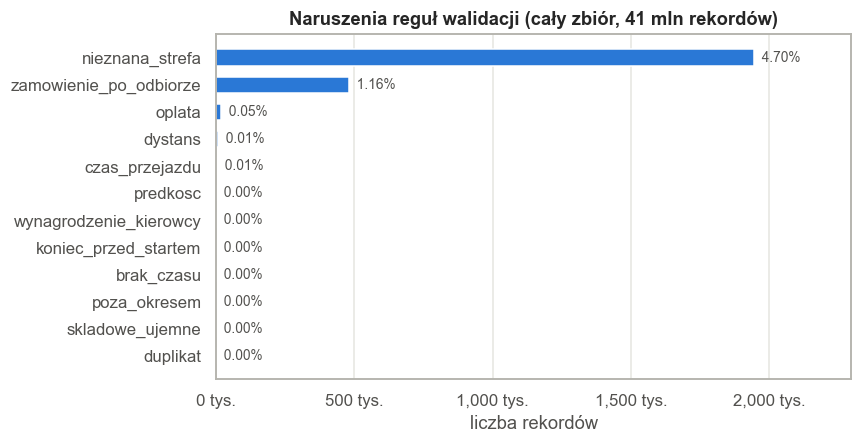

,liczba,%_wszystkich
nieznana_strefa,1946500,4.70
zamowienie_po_odbiorze,480089,1.16
oplata,19340,0.05
dystans,5171,0.01
czas_przejazdu,3946,0.01
predkosc,137,0.00
wynagrodzenie_kierowcy,6,0.00
koniec_przed_startem,2,0.00
brak_czasu,0,0.00
poza_okresem,0,0.00


In [11]:
quality = (pd.Series(report["naruszenia_regul"], name="liczba")
           .to_frame()
           .assign(**{"%_wszystkich": lambda d: d["liczba"] / report["wczytane"] * 100})
           .sort_values("liczba", ascending=False))
summary = pd.Series({k: report[k] for k in ["wczytane", "odrzucone", "czyste", "zaimportowane"]})
print(summary.map("{:,}".format).to_string())
print(f"Odrzucono {report['odrzucone'] / report['wczytane']:.2%} rekordów; "
      f"frakcja próbki zaimportowanej do MongoDB: {report['sample_fraction']:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
q = quality.sort_values("liczba")
ax.barh(q.index, q["liczba"], color=SERIES[0], height=0.6)
for y, (n, p) in enumerate(zip(q["liczba"], q["%_wszystkich"])):
    ax.text(n, y, f"  {p:.2f}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Naruszenia reguł walidacji (cały zbiór, 41 mln rekordów)")
ax.set_xlabel("liczba rekordów")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f} tys."))
ax.grid(axis="y", visible=False)
ax.set_xlim(right=q["liczba"].max() * 1.18)
plt.tight_layout()
plt.show()
quality

## 5. Analizy statystyczne

Oryginalna kolekcja `fhvhv_trips` zawiera miliony dokumentów.
Operacje `$group` i `$median` wykonywane na całym zbiorze doprowadzały do zerwania połączenia z MongoDB.

Zamiast wielokrotnych pełnych agregacji najpierw pobieramy **jedną losową próbkę z oryginalnej bazy**
przez `$sample` jako **pierwszy etap** zapytania, zapisujemy ją w osobnej lokalnej kolekcji
`analysis_sample_*` i wykorzystujemy ponownie w analizach 5–6 oraz dziennym ETL do Atlasa.

- **Dane oryginalne pozostają bez zmian.**
- Domyślnie analizujemy **30 000 przejazdów**, a nie wszystkie miliony.
- **Średnie, mediany, korelacje, procenty i udziały** są oszacowaniami na próbie; liczebności populacji są **ekstrapolacjami**, nie dokładnymi zliczeniami.
- Wyniki testów statystycznych dotyczą próby; losowanie i wstępne czyszczenie są źródłami niepewności.
- Wartość 5+ GiB dotyczy nadal kolekcji źródłowej; mała kolekcja analityczna **nie zastępuje jej**.


In [12]:
import hashlib
from itertools import islice
from pymongo.errors import BulkWriteError

ANALYSIS_SAMPLE_SIZE = 30_000
ANALYSIS_BATCH_SIZE = 500
MAX_SAMPLE_ROUNDS = 12
SOURCE_TRIP_COUNT = trips.estimated_document_count()
if SOURCE_TRIP_COUNT < 100:
    raise RuntimeError("Za mało dokumentów w oryginalnej kolekcji fhvhv_trips.")

analysis_target = min(int(ANALYSIS_SAMPLE_SIZE), max(1, int(SOURCE_TRIP_COUNT * 0.04)))
analysis_tag = hashlib.sha256(
    f"{DB_NAME}:{TRIPS}:{SOURCE_TRIP_COUNT}:{report.get('import_signature', '')}".encode()
).hexdigest()[:12]
analysis_name = f"analysis_sample_{analysis_tag}_{analysis_target}"
analysis_trips = db[analysis_name]
analysis_states = db["analysis_sample_state"]
analysis_state = analysis_states.find_one({"_id": analysis_name})
current_sample_count = analysis_trips.count_documents({})

if current_sample_count > analysis_target:
    raise RuntimeError(
        f"Próbka {analysis_name} ma {current_sample_count:,} rekordów, "
        f"czyli więcej niż wymagane {analysis_target:,}. "
        "Nie zmieniam jej automatycznie — sprawdź stan kolekcji."
    )

cache_ok = (
    analysis_state is not None
    and analysis_state.get("completed") is True
    and analysis_state.get("source_count") == SOURCE_TRIP_COUNT
    and current_sample_count == analysis_target
)

if cache_ok:
    print(f"[CACHE] Próbka jest już gotowa: {analysis_name} ({current_sample_count:,} dokumentów).")
else:
    print(f"[PRÓBKA] {analysis_name}: istnieje {current_sample_count:,}/{analysis_target:,}. ")
    analysis_states.update_one(
        {"_id": analysis_name},
        {"$set": {
            "completed": False,
            "source_count": SOURCE_TRIP_COUNT,
            "sample_count": analysis_target,
            "source_collection": TRIPS,
            "sample_collection": analysis_name,
        }},
        upsert=True,
    )

    for round_no in range(1, MAX_SAMPLE_ROUNDS + 1):
        missing = analysis_target - current_sample_count
        if missing == 0:
            break

        print(f"[PRÓBKA] Losowanie {round_no}: brakuje {missing:,} unikatowych rekordów...")
        cursor = trips.aggregate(
            [{"$sample": {"size": missing}}],
            allowDiskUse=False,
            batchSize=ANALYSIS_BATCH_SIZE,
            maxTimeMS=180_000,
        )
        added_this_round = 0
        duplicates_this_round = 0
        try:
            while True:
                chunk = list(islice(cursor, ANALYSIS_BATCH_SIZE))
                if not chunk:
                    break
                try:
                    result = analysis_trips.insert_many(chunk, ordered=False)
                    added_this_round += len(result.inserted_ids)
                except BulkWriteError as exc:
                    details = exc.details or {}
                    errors = details.get("writeErrors", [])
                    # Ignorujemy WYŁĄCZNIE E11000; wszystkie inne błędy zgłaszamy.
                    if details.get("writeConcernErrors") or not errors or any(
                        e.get("code") != 11000 for e in errors
                    ):
                        raise
                    added_this_round += int(details.get("nInserted", 0))
                    duplicates_this_round += len(errors)
        finally:
            cursor.close()

        # count_documents jest dokładne i tanie, bo próbka ma maks. 30 tys. rekordów.
        current_sample_count = analysis_trips.count_documents({})
        print(f"  zapisane nowe={added_this_round:,}; powtórzenia={duplicates_this_round:,}; "
              f"stan={current_sample_count:,}/{analysis_target:,}")

    if current_sample_count != analysis_target:
        raise RuntimeError(
            f"Próbka ma {current_sample_count:,}/{analysis_target:,} dokumentów. "
            "Dane pozostają zapisane — ponownie uruchom tę komórkę, aby dolosować brakujące."
        )

    analysis_states.update_one(
        {"_id": analysis_name},
        {"$set": {
            "completed": True,
            "source_count": SOURCE_TRIP_COUNT,
            "sample_count": analysis_target,
            "source_collection": TRIPS,
            "sample_collection": analysis_name,
        }},
        upsert=True,
    )
    print("[OK] Dokładnie 30 000 unikatowych dokumentów (lub mniej, jeśli źródło jest mniejsze).")

ANALYSIS_COUNT = analysis_trips.count_documents({})
ANALYSIS_SAMPLE_FRACTION = ANALYSIS_COUNT / SOURCE_TRIP_COUNT
EFFECTIVE_SOURCE_FRACTION = float(report["sample_fraction"]) * ANALYSIS_SAMPLE_FRACTION

print(f"Oryginał: {SOURCE_TRIP_COUNT:,} | Próbka: {ANALYSIS_COUNT:,} "
      f"({ANALYSIS_SAMPLE_FRACTION:.3%} kolekcji MongoDB)")
print(f"Szacowana frakcja źródła Parquet: {EFFECTIVE_SOURCE_FRACTION:.5%}")


def agg(pipeline, **kwargs):
    """MongoDB agreguje tylko trwałą, małą próbkę — nie pełne fhvhv_trips."""
    return pd.DataFrame(list(analysis_trips.aggregate(
        pipeline, allowDiskUse=False, maxTimeMS=90_000, **kwargs
    )))


def sample_docs(n, match=None, fields=()):
    """Próba do testów i wykresów z utrwalonych dokumentów MongoDB."""
    projection = {"_id": 0, **{col: 1 for col in fields}}
    rows = list(analysis_trips.find(match or {}, projection).batch_size(1_000))
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError(f"Brak rekordów w próbce analitycznej dla filtra {match}.")
    return frame.sample(n=min(int(n), len(frame)), random_state=RANDOM_SEED).reset_index(drop=True)

print("[BEZPIECZNIE] Analizy korzystają wyłącznie z małej kolekcji:", analysis_name)


[CACHE] Próbka jest już gotowa: analysis_sample_e034cb31e710_30000 (30,000 dokumentów).
Oryginał: 6,376,538 | Próbka: 30,000 (0.470% kolekcji MongoDB)
Szacowana frakcja źródła Parquet: 0.07882%
[BEZPIECZNIE] Analizy korzystają wyłącznie z małej kolekcji: analysis_sample_e034cb31e710_30000


### 5.1. Udział przewoźników w rynku i podział opłaty między pasażera i kierowcę

**Uwaga:** `przejazdy` oznacza liczbę przejazdów *w próbce analitycznej*, a nie dokładną liczbę kursów w oryginalnej kolekcji. Udział procentowy jest oszacowaniem.


In [13]:
providers = agg([
    {"$group": {
        "_id": {"provider": "$provider", "month": "$month"},
        "przejazdy": {"$sum": 1},
        "sr_oplata_bazowa": {"$avg": "$base_passenger_fare"},
        "mediana_oplaty": {"$median": {"input": "$base_passenger_fare", "method": "approximate"}},
        "sr_oplata_calkowita": {"$avg": "$total_fare"},
        "sr_wyplata_kierowcy": {"$avg": "$driver_pay"},
        "sr_udzial_kierowcy": {"$avg": "$driver_share"},
        "sr_dystans_mile": {"$avg": "$trip_miles"},
        "sr_oczekiwanie_min": {"$avg": "$wait_minutes"},
    }},
    {"$sort": {"_id.month": 1, "przejazdy": -1}},
])
providers = pd.concat([pd.json_normalize(providers["_id"]), providers.drop(columns="_id")], axis=1)
providers["udzial_w_rynku_%"] = providers["przejazdy"] / providers.groupby("month")["przejazdy"].transform("sum") * 100
providers["przejazdy_szac_lokalnie"] = providers["przejazdy"] / ANALYSIS_SAMPLE_FRACTION
providers["przejazdy_szac_zrodlo"] = providers["przejazdy"] / EFFECTIVE_SOURCE_FRACTION
providers

,provider,month,przejazdy,sr_oplata_bazowa,mediana_oplaty,sr_oplata_calkowita,sr_wyplata_kierowcy,sr_udzial_kierowcy,sr_dystans_mile,sr_oczekiwanie_min,udzial_w_rynku_%,przejazdy_szac_lokalnie,przejazdy_szac_zrodlo
0,Uber,2026-07,12425,25.18,18.57,30.64,19.56,0.82,4.39,5.50,72.87,"2,640,949.49","15,762,920.77"
1,Lyft,2026-07,4627,24.02,18.30,28.74,17.89,0.74,4.14,5.21,27.13,"983,474.71","5,870,022.89"
2,Uber,2026-08,9365,24.49,18.49,29.70,19.23,0.82,4.40,5.44,72.33,"1,990,542.61","11,880,865.43"
3,Lyft,2026-08,3583,23.29,17.81,27.73,17.62,0.76,4.08,5.08,27.67,"761,571.19","4,545,556.95"


Z tabeli można zaobserwować, że Uber miał ponad dwa razy więcej przejazdów aniżeli Lyft. Dodatkowo kierowcy Ubera zarabiali więcej aniżeli kierowcy Lyfta, jednocześnie Uber liczy sobie więcej za przejazd. Co więcej przejazdy Uberem były dłuższe i też się na nie dłużej czekało w porównaniu do przejazdów Lyft.

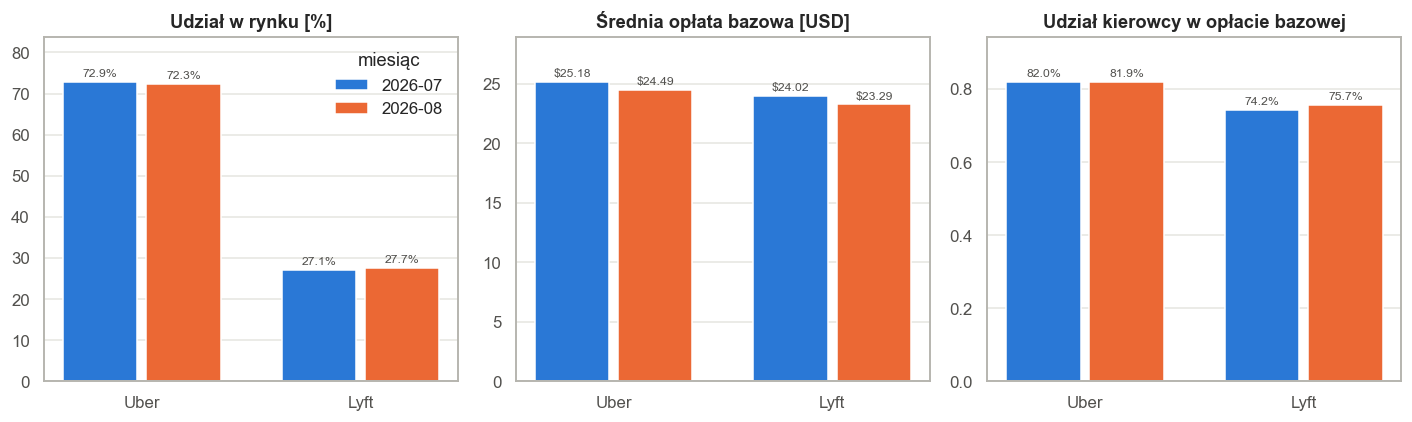

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
order = providers.groupby("provider")["przejazdy"].sum().sort_values(ascending=False).index
months = sorted(providers["month"].unique())
width = 0.38
x = np.arange(len(order))
metrics = [("udzial_w_rynku_%", "Udział w rynku [%]", "{:.1f}%"),
           ("sr_oplata_bazowa", "Średnia opłata bazowa [USD]", "${:.2f}"),
           ("sr_udzial_kierowcy", "Udział kierowcy w opłacie bazowej", "{:.1%}")]
for ax, (col, title, fmt) in zip(axes, metrics):
    for j, m in enumerate(months):
        vals = providers[providers["month"] == m].set_index("provider").reindex(order)[col]
        bars = ax.bar(x + (j - 0.5) * width, vals, width - 0.04, color=MONTH_COLORS[m], label=m)
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals], fontsize=8, color="#52514e", padding=2)
    ax.set_xticks(x, order)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
axes[0].legend(title="miesiąc", frameon=False)
plt.tight_layout()
plt.show()

Na wykresach można zaobserwować przewagę Ubera nad Lyftem w kwestii udziału na rynku, dodatkowo ci dwaj przewoźnicy są jedynymi przewoźnikami w badanych miesiącach. Udział kierowcy w opłacie bazowej dla kierowcy Ubera jest w przedziale około od 82% do 83%, gdzie dla kierowcy Lyfta jest to już około od 74% do 75.5%. Średnio kierowca Ubera zarabia więcej niż kierowca Lyfta.


W celu sprawdzenia statystycznej istotności różnicy pomiędzy kolumnami `driver_share` oraz `fare_per_mile` w zależności od przewoźnika wykorzystano test Mann Whitneya wzbogaconego o korelacje rangowo-dwuseryjną w celu określenia mocy ewentualnego efektu. Poziom istotności dla testu wynosi $\alpha=0.05$


In [15]:
samples = {p: sample_docs(50_000, {"provider": p}, ["driver_share", "fare_per_mile"]) for p in ["Uber", "Lyft"]}
rows = []
for col in ["driver_share", "fare_per_mile"]:
    a, b = samples["Uber"][col], samples["Lyft"][col]
    u, p_val = stats.mannwhitneyu(a, b, alternative="two-sided")
    effect = 1 - 2 * u / (len(a) * len(b))
    rows.append({"zmienna": col, "U": u, "p_value": p_val, "efekt_rank_biserial": effect})
pd.DataFrame(rows).set_index("zmienna")

,U,p_value,efekt_rank_biserial
zmienna,,,
driver_share,"99,402,399.00",0.00,-0.11
fare_per_mile,"83,447,084.00",0.00,0.07


Test Manna-Whitneya daje p-value ≈ 0 dla obu zmiennych, a więc jest mniejszy od przyjętego poziomu istotności, co pozwala na odrzucenie hipotezy zerowej w obydwu przypadkach. Wpływ różnicy dla zmiennej `fare_per_mile` jest znikomy, natomiast dla zmiennej `driver_share` jest mały.


### 5.2. Popyt w ciągu tygodnia i doby, czas oczekiwania i prędkość

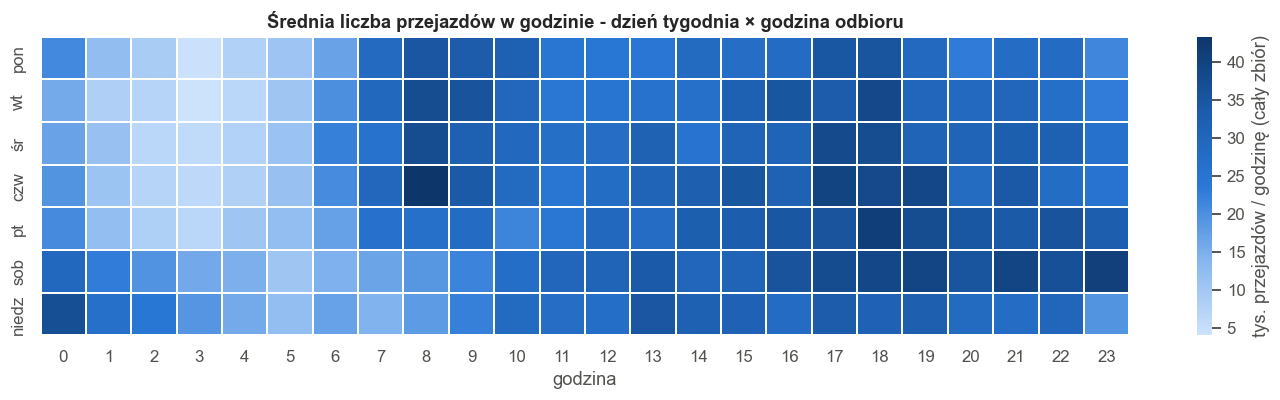

In [16]:
hourly = agg([
    {"$group": {
        "_id": {"dow": "$pickup_dow", "hour": "$pickup_hour"},
        "przejazdy": {"$sum": 1},
        "sr_oczekiwanie_min": {"$avg": "$wait_minutes"},
        "sr_predkosc_mph": {"$avg": "$speed_mph"},
    }},
])
hourly = pd.concat([pd.json_normalize(hourly["_id"]), hourly.drop(columns="_id")], axis=1)
DOW_NAMES = {1: "pon", 2: "wt", 3: "śr", 4: "czw", 5: "pt", 6: "sob", 7: "niedz"}
dow_days = pd.Series(pd.date_range(PERIOD_START, PERIOD_END - pd.Timedelta(days=1)).dayofweek + 1).value_counts()
hourly["przejazdy_na_dzien"] = hourly["przejazdy"] / hourly["dow"].map(dow_days) / EFFECTIVE_SOURCE_FRACTION
heat = hourly.pivot(index="dow", columns="hour", values="przejazdy_na_dzien").rename(index=DOW_NAMES)

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat / 1000, cmap=BLUES, ax=ax, linewidths=1, linecolor="white",
            cbar_kws={"label": "tys. przejazdów / godzinę (cały zbiór)"})
ax.set_title("Średnia liczba przejazdów w godzinie - dzień tygodnia × godzina odbioru")
ax.set_xlabel("godzina")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Na mapie ciepła można zaobserwować, że w dni robocze w godzinach porannych, czyli około 8, oraz popołudniowych, 17:00-18:00 występuje wzmożony ruch. W piątek i sobotę ruch utrzymuje się do późnej nocy. Co więcej, największy ruch przypada na noc z soboty na niedziele. Natomiast godziny poranne w weekendy charakteryzują się mniejszym ruchem w porównaniu do reszty tygodnia.


W celu sprawdzenia zależności pomiędzy natężeniem ruchu a średnią prędkością oraz średnim czasem oczekiwania na kierowcę wykorzystano korelację Spearmana.

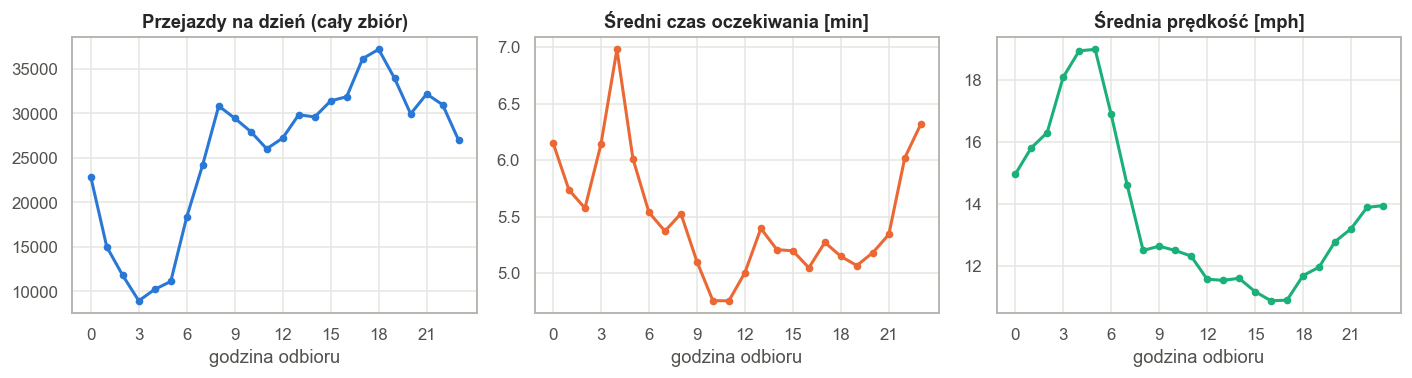

Spearman (natężenie vs prędkość), n = 168 godzin tygodnia: rho = -0.777, p = 3.92e-35
Spearman (natężenie vs czas oczekiwania): rho = -0.117, p = 1.32e-01


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
przejazdy_na_dzien,"22,856.08","14,998.66","11,786.13","8,941.90","10,231.01","11,110.88","18,354.44","24,227.04","30,815.81","29,444.85","27,951.13","26,007.23","27,214.49","29,833.63","29,588.09","31,388.75","31,859.37","36,135.94","37,179.50","33,905.58","29,935.94","32,166.30","30,959.04","26,968.95"
sr_oczekiwanie_min,6.15,5.74,5.57,6.14,6.98,6.01,5.54,5.37,5.53,5.10,4.75,4.75,5.00,5.39,5.21,5.20,5.05,5.27,5.15,5.07,5.18,5.34,6.02,6.32
sr_predkosc_mph,14.95,15.80,16.30,18.08,18.93,18.98,16.89,14.62,12.50,12.64,12.50,12.32,11.58,11.54,11.61,11.18,10.88,10.90,11.69,11.96,12.79,13.20,13.89,13.95


In [17]:
weighted = hourly.assign(
    wait_x_n=hourly["sr_oczekiwanie_min"] * hourly["przejazdy"],
    speed_x_n=hourly["sr_predkosc_mph"] * hourly["przejazdy"],
).groupby("hour")[["przejazdy", "wait_x_n", "speed_x_n"]].sum()
by_hour = pd.DataFrame({
    "przejazdy_na_dzien": weighted["przejazdy"] / EFFECTIVE_SOURCE_FRACTION / dow_days.sum(),
    "sr_oczekiwanie_min": weighted["wait_x_n"] / weighted["przejazdy"],
    "sr_predkosc_mph": weighted["speed_x_n"] / weighted["przejazdy"],
})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (col, title, color) in zip(axes, [
        ("przejazdy_na_dzien", "Przejazdy na dzień (cały zbiór)", SERIES[0]),
        ("sr_oczekiwanie_min", "Średni czas oczekiwania [min]", SERIES[1]),
        ("sr_predkosc_mph", "Średnia prędkość [mph]", SERIES[2])]):
    ax.plot(by_hour.index, by_hour[col], color=color, lw=2, marker="o", ms=4)
    ax.set_title(title)
    ax.set_xlabel("godzina odbioru")
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()

rho, p_val = stats.spearmanr(hourly["przejazdy_na_dzien"], hourly["sr_predkosc_mph"])
rho_w, p_w = stats.spearmanr(hourly["przejazdy_na_dzien"], hourly["sr_oczekiwanie_min"])
print(f"Spearman (natężenie vs prędkość), n = {len(hourly)} godzin tygodnia: rho = {rho:.3f}, p = {p_val:.2e}")
print(f"Spearman (natężenie vs czas oczekiwania): rho = {rho_w:.3f}, p = {p_w:.2e}")
by_hour.round(2).T

Na wykresach można zaobserwować, że najmniej przejazdów odbywa się około godziny 3, natomiast najwięcej o 18:00. Można zaobserwować, że średnia prędkosć jazdy spada wraz ze wzrostem przejazdów na dzień, taką sytuację moga powodować korki występujące w godzinach popołudniowych. Potwierdza to korelacja Spearmana, która wskazuje na silną ujemna zależność.

Czas oczekiwania na kierowcę jest najdłuższy w nocy i nad ranem, gdzie wynosi od 6 do 7 min, a najkrótszy przed południem około 4.5 minuty. Jego korelacja z natężeniem ruchu jest słaba, co oznacza, że liczba kierowców dostosowuje się do popytu, a w nocy po prostu jest ich mniej.


### 5.3. Od czego zależy cena przejazdu? Dystans i ceny w dzielnicach

Wersja 4.0.2: poniższe kwartyle i liczebności liczone są na małej próbie, dlatego mogą różnić się od historycznych wyników dla pełnej kolekcji.


In [18]:
boroughs = agg([
    {"$match": {"pu_borough": {"$nin": [None, "Unknown", "N/A"]}}},
    {"$group": {
        "_id": "$pu_borough",
        "przejazdy": {"$sum": 1},
        "oplata_pct": {"$percentile": {"input": "$base_passenger_fare", "p": [0.25, 0.5, 0.75], "method": "approximate"}},
        "cena_za_mile_pct": {"$percentile": {"input": "$fare_per_mile", "p": [0.25, 0.5, 0.75], "method": "approximate"}},
        "sr_dystans": {"$avg": "$trip_miles"},
        "udzial_lotnisko": {"$avg": {"$cond": ["$is_airport_trip", 1, 0]}},
        "udzial_oplata_cbd": {"$avg": {"$cond": [{"$gt": ["$cbd_congestion_fee", 0]}, 1, 0]}},
    }},
    {"$sort": {"przejazdy": -1}},
]).rename(columns={"_id": "dzielnica"}).set_index("dzielnica")
for col in ["oplata_pct", "cena_za_mile_pct"]:
    boroughs[[f"{col}_Q1", f"{col}_mediana", f"{col}_Q3"]] = pd.DataFrame(boroughs[col].tolist(), index=boroughs.index)
boroughs = boroughs.drop(columns=["oplata_pct", "cena_za_mile_pct"])
boroughs

,przejazdy,sr_dystans,udzial_lotnisko,udzial_oplata_cbd,oplata_pct_Q1,oplata_pct_mediana,oplata_pct_Q3,cena_za_mile_pct_Q1,cena_za_mile_pct_mediana,cena_za_mile_pct_Q3
dzielnica,,,,,,,,,,
Manhattan,10237,4.27,0.07,0.76,14.33,21.98,34.15,5.35,7.74,11.29
Brooklyn,8317,3.83,0.04,0.09,10.78,16.68,27.11,5.28,6.75,8.47
Queens,6914,5.23,0.19,0.10,10.78,17.92,33.24,4.39,5.86,7.55
Bronx,4037,3.82,0.01,0.03,9.87,14.39,21.63,4.25,5.84,7.73
Staten Island,495,4.72,0.02,0.02,9.83,15.36,25.02,4.14,5.35,6.59


Z tabeli można zaobserwować, że najwięcej przejazdów rozpoczyna się na Manhattanie, a najmniej na Staten Island. Biorąc pod uwagę medianę opłat, najtańsze przejazdy były w Bronksie oraz Staten Island wynoszące około 14.6 USD, natomiast najdroższe na Manhattanie wynoszące około 22.2 USD. Najdłuższe są średnio przejazdy z Queens, gdzie około 19% kursów to przejazdy z lub do lotniska. Dodatkowo około 76% kursów z Manhattanu objętych jest opłatą za wjazd do strefy CBD, podczas gdy w pozostałych dzielnicach jest to co najwyżej około 10%.


Współczynniki korelacji Pearsona i Spearmana liczymy na przejazdach z trwałej
**próbki analitycznej MongoDB** (maksymalnie `ANALYSIS_SAMPLE_SIZE`, domyślnie 30 tys.).
Wartości z poprzedniej wersji na 200 tys. rekordów nie są bezpośrednio porównywalne.

Pearson r(dystans, opłata) = 0.824 (p = 0.0e+00)
Spearman rho(dystans, opłata) = 0.847 (p = 0.0e+00)


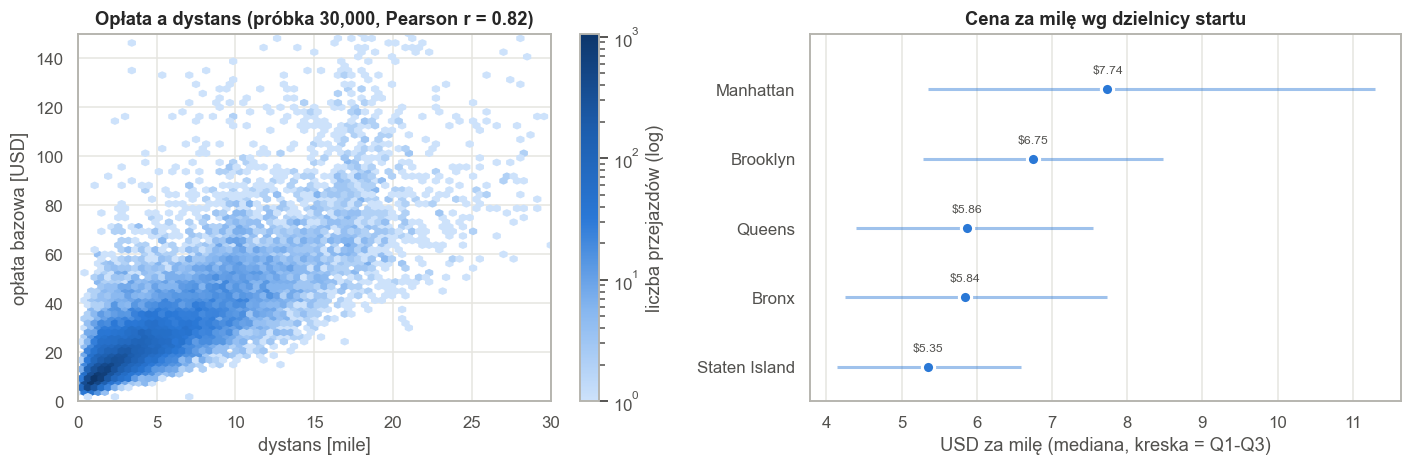

In [19]:
fares = sample_docs(200_000, None, ["trip_miles", "base_passenger_fare", "pu_borough"])
pearson_r, pearson_p = stats.pearsonr(fares["trip_miles"], fares["base_passenger_fare"])
spearman_r, spearman_p = stats.spearmanr(fares["trip_miles"], fares["base_passenger_fare"])
print(f"Pearson r(dystans, opłata) = {pearson_r:.3f} (p = {pearson_p:.1e})")
print(f"Spearman rho(dystans, opłata) = {spearman_r:.3f} (p = {spearman_p:.1e})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
hb = ax.hexbin(fares["trip_miles"], fares["base_passenger_fare"], gridsize=70, cmap=BLUES, mincnt=1,
               bins="log", extent=(0, 30, 0, 150))
ax.set_xlim(0, 30); ax.set_ylim(0, 150)
ax.set_xlabel("dystans [mile]"); ax.set_ylabel("opłata bazowa [USD]")
ax.set_title(f"Opłata a dystans (próbka {len(fares):,}, Pearson r = {pearson_r:.2f})")
fig.colorbar(hb, ax=ax, label="liczba przejazdów (log)")

ax = axes[1]
b = boroughs.sort_values("cena_za_mile_pct_mediana")
yy = np.arange(len(b))
ax.hlines(yy, b["cena_za_mile_pct_Q1"], b["cena_za_mile_pct_Q3"], color=SERIES[0], lw=2, alpha=0.45)
ax.plot(b["cena_za_mile_pct_mediana"], yy, "o", color=SERIES[0], ms=8, markeredgecolor="white", markeredgewidth=2)
for i, v in enumerate(b["cena_za_mile_pct_mediana"]):
    ax.text(v, i + 0.22, f"${v:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_yticks(yy, b.index)
ax.set_ylim(-0.5, len(b) - 0.2)
ax.set_xlabel("USD za milę (mediana, kreska = Q1-Q3)")
ax.set_title("Cena za milę wg dzielnicy startu")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Współczynnik korelacji Pearsona wynosi r ≈ 0,82, a Spearmana ρ ≈ 0,84 (p-value < 0,001), co oznacza silną dodatnią zależność - co wskazuje, że im dalszy jest przejazd tym wyższa będzie opłata. Ważną obserwacją jest to, że punkty na wykresie są porozrzucane, co oznacza, że na tym samym dystansie ceny się różnią. Jest tak ponieważ nie tylko dystans, ale i inne czynniki jak mają wpływ na cenę przejazdu.

Na wykresie po prawej można zaobserwować, że najdroższa mila jest na Manhattanie z medianą około 7,75 USD. Występuje tam też największy rozrzut cen. Następnie w Brooklynie mediana wynosi około 6,78 USD. W Queens, Bronksie i na Staten Island mediana wynosi od około 5,40 do 5,80 USD za milę.


W celu sprawdzenia statystycznej istotności różnicy ceny za milę (`fare_per_mile`) pomiędzy dzielnicami wykorzystano test Kruskala-Wallisa wzbogacony o współczynnik ε² w celu określenia siły ewentualnego efektu.

In [20]:
fares["fare_per_mile"] = fares["base_passenger_fare"] / fares["trip_miles"]
groups = [g["fare_per_mile"].to_numpy() for name, g in fares.groupby("pu_borough")
          if len(g) > 100 and name not in ("Unknown", "N/A")]
h, p_kw = stats.kruskal(*groups)
eps2 = (h - len(groups) + 1) / (sum(map(len, groups)) - len(groups))
print(f"Kruskal-Wallis: H = {h:,.0f}, p = {p_kw:.1e}, epsilon² = {eps2:.3f} ({len(groups)} dzielnic)")

Kruskal-Wallis: H = 2,055, p = 0.0e+00, epsilon² = 0.068 (5 dzielnic)


Test Kruskala-Wallisa daje p-value ≈ 0, a więc jest mniejszy od przyjętego poziomu istotności α = 0,05, co pozwala na odrzucenie hipotezy zerowej - cena za milę różni się istotnie pomiędzy dzielnicami. Siła efektu jest jednak mała, bliska umiarkowanej (ε² ≈ 0,07).

### 5.4. Napiwki: kto i kiedy je daje?

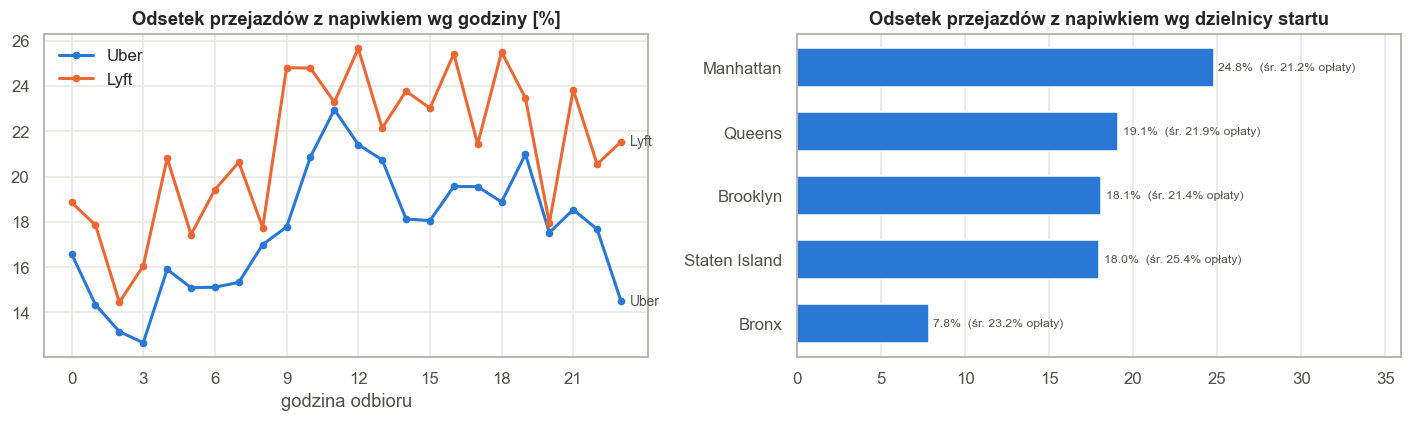

,przejazdy,odsetek_z_napiwkiem,sr_napiwek_usd,sr_napiwek_pct
dzielnica,,,,
Manhattan,10237,24.80,5.94,21.19
Queens,6914,19.11,6.44,21.87
Brooklyn,8317,18.08,4.81,21.39
Staten Island,495,17.98,4.91,25.38
Bronx,4037,7.83,4.39,23.21


In [21]:
tips_hour = agg([
    {"$group": {
        "_id": {"provider": "$provider", "hour": "$pickup_hour"},
        "przejazdy": {"$sum": 1},
        "z_napiwkiem": {"$sum": {"$cond": [{"$gt": ["$tips", 0]}, 1, 0]}},
        "sr_napiwek_pct": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tip_pct", None]}},
    }},
])
tips_hour = pd.concat([pd.json_normalize(tips_hour["_id"]), tips_hour.drop(columns="_id")], axis=1)
tips_hour["odsetek_z_napiwkiem"] = tips_hour["z_napiwkiem"] / tips_hour["przejazdy"] * 100

tips_borough = agg([
    {"$match": {"pu_borough": {"$nin": [None, "Unknown", "N/A"]}}},
    {"$group": {
        "_id": "$pu_borough",
        "przejazdy": {"$sum": 1},
        "odsetek_z_napiwkiem": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, 100, 0]}},
        "sr_napiwek_usd": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tips", None]}},
        "sr_napiwek_pct": {"$avg": {"$cond": [{"$gt": ["$tips", 0]}, "$tip_pct", None]}},
    }},
    {"$sort": {"odsetek_z_napiwkiem": -1}},
]).rename(columns={"_id": "dzielnica"}).set_index("dzielnica")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for prov in [p for p in ["Uber", "Lyft"] if p in set(tips_hour["provider"])]:
    d = tips_hour[tips_hour["provider"] == prov].sort_values("hour")
    axes[0].plot(d["hour"], d["odsetek_z_napiwkiem"], lw=2, marker="o", ms=4, color=PROVIDER_COLORS[prov], label=prov)
    axes[0].annotate(prov, (d["hour"].iloc[-1], d["odsetek_z_napiwkiem"].iloc[-1]), xytext=(6, 0),
                     textcoords="offset points", va="center", fontsize=9, color="#52514e")
axes[0].set_title("Odsetek przejazdów z napiwkiem wg godziny [%]")
axes[0].set_xlabel("godzina odbioru"); axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(frameon=False)
tb = tips_borough.sort_values("odsetek_z_napiwkiem")
bars = axes[1].barh(tb.index, tb["odsetek_z_napiwkiem"], color=SERIES[0], height=0.6)
axes[1].bar_label(bars, labels=[f"{v:.1f}%  (śr. {s:.1f}% opłaty)" for v, s in
                                zip(tb["odsetek_z_napiwkiem"], tb["sr_napiwek_pct"])],
                  fontsize=8, color="#52514e", padding=3)
axes[1].set_title("Odsetek przejazdów z napiwkiem wg dzielnicy startu")
axes[1].set_xlim(right=tb["odsetek_z_napiwkiem"].max() * 1.45)
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
tips_borough

Na wykresie po lewej można zaobserwować, że pasażerowie Lyfta o każdej porze doby nieco częściej dają napiwki niż pasażerowie Ubera. Najwięcej napiwków jest w godzinach południowych a najmniej około 3:00 w nocy.

Na wykresie po prawej oraz w tabeli można zaobserwować duże różnice pomiędzy dzielnicami. Na Manhattanie napiwek pojawia się w około 25% kursów, natomiast w Bronksie tylko w około 8%. Ciekawą obserwacją jest fakt, że jeśli już napiwek się pojawi to mieści się w zakresie od około 20% do 23% ceny bazowej.


W celu sprawdzenia, czy kursy lotniskowe istotnie częściej kończą się napiwkiem niż pozostałe, wykorzystano test niezależności chi-kwadrat wzbogacony o współczynnik V Craméra w celu określenia siły ewentualnego związku.

In [22]:
ct = agg([
    {"$group": {"_id": {"lotnisko": "$is_airport_trip", "tip": {"$gt": ["$tips", 0]}}, "n": {"$sum": 1}}},
])
ct = (pd.concat([pd.json_normalize(ct["_id"]), ct["n"]], axis=1)
      .pivot(index="lotnisko", columns="tip", values="n").fillna(0))
ct.columns = ["bez napiwku", "z napiwkiem"]
ct.index = ct.index.map({False: "pozostałe kursy", True: "kursy lotniskowe"})
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
ct["% z napiwkiem"] = ct["z napiwkiem"] / ct.sum(axis=1) * 100
print(f"Chi² = {chi2:,.0f}, df = {dof}, p = {p:.1e}, V Craméra = {cramers_v:.3f}")
ct

Chi² = 260, df = 1, p = 1.5e-58, V Craméra = 0.093


,bez napiwku,z napiwkiem,% z napiwkiem
lotnisko,,,
pozostałe kursy,22561,4998,18.14
kursy lotniskowe,1670,771,31.59


Z tabeli można zaobserwować, że kursy lotniskowe kończą się napiwkiem prawie dwa razy częściej niż pozostałe. Test chi-kwadrat daje p-value ≈ 0, a więc jest mniejszy od przyjętego poziomu istotności α = 0,05, co pozwala na odrzucenie hipotezy zerowej o niezależności. Siła związku jest słaba, jednak różnica jest wyraźnie widoczna.


### 5.5. Najpopularniejsze trasy między strefami

Trasy i częstości pochodzą z losowej próbki; `przejazdy_szac` jest ekstrapolacją, a nie dokładnym licznikiem przejazdów.


Przejazdy w obrębie jednej strefy: 8.3%


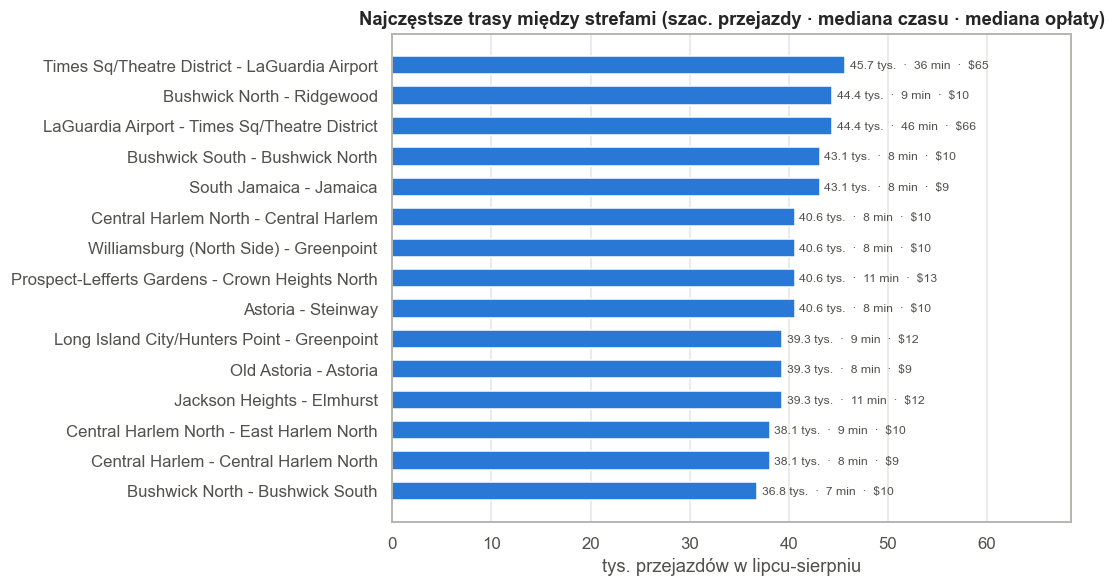

,trasa,przejazdy_szac,mediana_min,mediana_oplaty
0,Times Sq/Theatre District - LaGuardia Airport,"45,671.24",36.20,65.06
1,Bushwick North - Ridgewood,"44,402.59",8.77,10.09
2,LaGuardia Airport - Times Sq/Theatre District,"44,402.59",46.12,66.22
3,Bushwick South - Bushwick North,"43,133.95",7.67,9.82
4,South Jamaica - Jamaica,"43,133.95",8.28,8.96
5,Central Harlem North - Central Harlem,"40,596.66",7.97,9.83
6,Williamsburg (North Side) - Greenpoint,"40,596.66",7.82,9.66
7,Prospect-Lefferts Gardens - Crown Heights North,"40,596.66",11.18,12.55
8,Astoria - Steinway,"40,596.66",7.52,10.15
9,Long Island City/Hunters Point - Greenpoint,"39,328.01",9.15,11.79


In [23]:
same_zone = agg([
    {"$group": {"_id": None, "n": {"$sum": 1},
                "ta_sama_strefa": {"$sum": {"$cond": [{"$eq": ["$pu_location_id", "$do_location_id"]}, 1, 0]}}}},
]).iloc[0]
print(f"Przejazdy w obrębie jednej strefy: {same_zone['ta_sama_strefa'] / same_zone['n']:.1%}")

routes = agg([
    {"$match": {"$expr": {"$ne": ["$pu_location_id", "$do_location_id"]}}},
    {"$group": {
        "_id": {"z": "$pu_zone", "do": "$do_zone"},
        "przejazdy": {"$sum": 1},
        "mediana_min": {"$median": {"input": "$trip_minutes", "method": "approximate"}},
        "mediana_oplaty": {"$median": {"input": "$base_passenger_fare", "method": "approximate"}},
    }},
    {"$sort": {"przejazdy": -1}},
    {"$limit": 15},
])
routes = pd.concat([pd.json_normalize(routes["_id"]), routes.drop(columns="_id")], axis=1)
routes["trasa"] = routes["z"] + " - " + routes["do"]
routes["przejazdy_szac"] = routes["przejazdy"] / EFFECTIVE_SOURCE_FRACTION

fig, ax = plt.subplots(figsize=(10, 5.5))
r = routes.iloc[::-1]
bars = ax.barh(r["trasa"], r["przejazdy_szac"] / 1000, color=SERIES[0], height=0.6)
ax.bar_label(bars, labels=[f"{n / 1000:.1f} tys.  ·  {m:.0f} min  ·  ${f:.0f}" for n, m, f in
                           zip(r["przejazdy_szac"], r["mediana_min"], r["mediana_oplaty"])],
             fontsize=8, color="#52514e", padding=3)
ax.set_title("Najczęstsze trasy między strefami (szac. przejazdy · mediana czasu · mediana opłaty)")
ax.set_xlabel("tys. przejazdów w lipcu-sierpniu")
ax.set_xlim(right=r["przejazdy_szac"].max() / 1000 * 1.5)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
routes[["trasa", "przejazdy_szac", "mediana_min", "mediana_oplaty"]]

Około 8% kursów zaczyna się i kończy w tej samej strefie. Na wykresie można zaobserwować, że najpopularniejsze trasy to krótkie przejazdy około 8-11 minut i 9-13 USD pomiędzy sąsiednimi strefami poza Manhattanem, np. Bushwick North - Bushwick South, Williamsburg - Greenpoint czy Jamaica - South Jamaica. Wyjątkiem jest trasa LaGuardia Airport- Times Sq/Theatre District, która trwa około 40 minut i kosztuje około 70 USD, przez co jest jedną z droższych tras w podanym porównaniu.


## 6. Podsumowanie

Najważniejsze obserwacje:

1. Uber ma ok. 72% rynku. Kierowcy Ubera dostają większą część opłaty bazowej ok. 82% wobec 75% w Lyfcie, a za milę Lyft jest nieco droższy.
2. Popyt ma silny rytm dobowy i tygodniowy. W godzinach szczytu średnia prędkość spada niemal o połowę.
3. Cena silnie zależy od dystansu. Najdroższa mila jest na Manhattanie.
4. Napiwki daje mniej niż 1 na 5 pasażerów. Najczęściej dają je pasażerowie kursów lotniskowych i z Manhattanu.
5. Najczęstsze trasy to krótkie przejazdy między sąsiednimi strefami poza Manhattanem, a wyjątkiem jest LaGuardia - Times Square.

Ograniczenia:

Analizy działają na losowej próbce ok. 18% oczyszczonych przejazdów, dlatego liczby bezwzględne są przeskalowane na cały zbiór. Dane nie zawierają cen dynamicznych ani informacji o pasażerach. Przy bardzo dużych próbkach istotność statystyczna jest niemal pewna, więc interpretujemy przede wszystkim wielkość efektu.

---
# CZĘŚĆ II - NA OCENĘ 4.0: DWIE BAZY, SCRAPING, ETL I ANALITYKA

In [24]:
import os
import re
import json
import hashlib
import calendar
from collections import Counter
from datetime import datetime, timezone
from urllib.parse import urljoin, urlsplit, unquote

import requests
import certifi
from bs4 import BeautifulSoup
from dotenv import load_dotenv
from pymongo import ReplaceOne
from pymongo.errors import PyMongoError

load_dotenv(".env", override=False)
ATLAS_URI = os.getenv("ATLAS_URI", "").strip()
RUN_WEB_SCRAPING = os.getenv("RUN_WEB_SCRAPING", "1") == "1"
REFRESH_DAILY = os.getenv("REFRESH_DAILY", "0") == "1"
RUN_EXTRA_MODEL = os.getenv("RUN_EXTRA_MODEL", "0") == "1"
RUN_LOCAL_DEMO = True

ATLAS_DB_NAME = "nyc_taxi_cloud"
SCRAPED_COLLECTION = "tlc_file_catalog"
DAILY_COLLECTION = "trip_daily_metrics"
SCRAPE_PAGE_URL = "https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page"
SCRAPE_FALLBACK_URL = "https://home4.nyc.gov/site/tlc/about/tlc-trip-record-data.page"
OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Lokalna baza:", DB_NAME, "/", TRIPS)
print("Atlas URI ustawiony:", bool(ATLAS_URI))
print("Web scraping włączony:", RUN_WEB_SCRAPING)
print("Wymuszone odświeżenie agregatów dziennych:", REFRESH_DAILY)

Lokalna baza: nyc_taxi / fhvhv_trips
Atlas URI ustawiony: True
Web scraping włączony: True
Wymuszone odświeżenie agregatów dziennych: False


## 8. Audyt skali danych i dwóch instancji

In [25]:
parquet_uncompressed = sum(
    merged.metadata.row_group(i).total_byte_size for i in range(merged.num_row_groups)
)
parquet_compressed = MERGED_FILE.stat().st_size
mongo_coll = db.command("collStats", TRIPS)
scale_audit = pd.DataFrame([
    {"zasób": "Parquet scalony (plik, skompresowany)", "bajty": parquet_compressed},
    {"zasób": "Parquet nieskompresowany (suma metadanych row groups)", "bajty": parquet_uncompressed},
    {"zasób": "MongoDB — logiczny rozmiar dokumentów BSON", "bajty": mongo_coll["size"]},
    {"zasób": "MongoDB — indeksy", "bajty": mongo_coll["totalIndexSize"]},
])
scale_audit["GiB"] = scale_audit["bajty"] / GIB
print("Rekordy w surowym Parquet:", f"{merged.metadata.num_rows:,}")
print("Rekordy w lokalnym MongoDB:", f"{mongo_coll['count']:,}")
print("Wymóg >= 5 GB nieskompresowanych danych źródłowych:",
      "TAK" if parquet_uncompressed >= 5_000_000_000 else "NIE / do wyjaśnienia")
print("MongoDB ma >= 5 GiB BSON:", mongo_coll["size"] >= 5 * GIB)
display(scale_audit)

Rekordy w surowym Parquet: 41,414,729
Rekordy w lokalnym MongoDB: 6,376,538
Wymóg >= 5 GB nieskompresowanych danych źródłowych: NIE / do wyjaśnienia
MongoDB ma >= 5 GiB BSON: True


,zasób,bajty,GiB
0,"Parquet scalony (plik, skompresowany)",999355703,0.93
1,Parquet nieskompresowany (suma metadanych row ...,1208876242,1.13
2,MongoDB — logiczny rozmiar dokumentów BSON,5731751301,5.34
3,MongoDB — indeksy,95625216,0.09


### 8.1. Kontrola dostępności Atlasa i bezpieczeństwa połączeń

In [26]:
atlas_client = None
atlas_db = None
atlas_enabled = False
if not ATLAS_URI:
    print("[POMINIĘTO] Brak ATLAS_URI w .env. Kod cloud jest gotowy, ale nie uruchomiony.")
else:
    try:
        atlas_client = MongoClient(
            ATLAS_URI, serverSelectionTimeoutMS=12_000,
            connectTimeoutMS=12_000, tlsCAFile=certifi.where(),
        )
        atlas_client.admin.command("ping")
        atlas_db = atlas_client[ATLAS_DB_NAME]
        atlas_enabled = True
        print("[OK] Połączono z MongoDB Atlas; baza:", ATLAS_DB_NAME)
    except (PyMongoError, ValueError) as exc:
        atlas_client = None
        print("[BŁĄD POŁĄCZENIA] Zweryfikuj ATLAS_URI, Network Access i Database Access.")
        print(type(exc).__name__, "— sprawdź dane dostępu, certyfikat i konfigurację sieci.")

local_ping = client.admin.command("ping")
print("MongoDB lokalne odpowiada na ping:", local_ping.get("ok") == 1)

[OK] Połączono z MongoDB Atlas; baza: nyc_taxi_cloud
MongoDB lokalne odpowiada na ping: True


## 9. Web scraping oficjalnego katalogu danych NYC TLC

In [27]:
LINK_PATTERN = re.compile(
    r"(?P<dataset>fhvhv|fhv|yellow|green)_tripdata_"
    r"(?P<year>20\d{2})-(?P<month>0[1-9]|1[0-2])\.parquet(?:$|[?#])",
    flags=re.IGNORECASE,
)
SERVICE_NAMES = {
    "fhvhv": "High Volume For-Hire Vehicle",
    "fhv": "For-Hire Vehicle",
    "yellow": "Yellow Taxi",
    "green": "Green Taxi",
}

def parse_tlc_html(html, page_url, captured_at=None):
    """Parsuje linki z HTML TLC. Zero wywołań sieciowych; łatwe testowanie."""
    if captured_at is None:
        captured_at = datetime.now(timezone.utc)
    soup = BeautifulSoup(html, "html.parser")
    extracted = {}
    for anchor in soup.select("a[href]"):
        href = anchor.get("href", "").strip()
        if href.startswith(("javascript:", "mailto:", "#")):
            continue
        target = urljoin(page_url, href)
        url_parts = urlsplit(target)
        if url_parts.scheme not in ("http", "https"):
            continue
        match = LINK_PATTERN.search(unquote(url_parts.path))
        if not match:
            continue
        kind, year, month = match.group("dataset", "year", "month")
        kind = kind.lower()
        period = f"{year}-{month}"
        identity = f"{kind}:{period}"
        record = {
            "_id": identity,
            "dataset": kind,
            "service": SERVICE_NAMES[kind],
            "month": period,
            "year": int(year),
            "file_url": target,
            "anchor_text": anchor.get_text(" ", strip=True)[:120],
            "source_page": page_url,
            "scraped_at": captured_at,
            "acquisition_method": "web_scraping_html_bs4",
        }
        extracted[identity] = record
    return sorted(extracted.values(), key=lambda d: d["_id"])

fixture_html = """<html><body>
<a href="https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_2026-07.parquet">HVFHV July</a>
<a href="/trip-data/yellow_tripdata_2026-08.parquet">Yellow August</a>
<a href="https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_2026-07.parquet">Duplicate</a>
<a href="mailto:test@example.org">Ignore</a>
</body></html>"""
fixture_docs = parse_tlc_html(fixture_html, SCRAPE_PAGE_URL)
assert len(fixture_docs) == 2
assert {d["_id"] for d in fixture_docs} == {"fhvhv:2026-07", "yellow:2026-08"}
print("[TEST OK] HTML parsing, typy przewozów i deduplikacja linków")
display(pd.DataFrame(fixture_docs).drop(columns="scraped_at"))

[TEST OK] HTML parsing, typy przewozów i deduplikacja linków


,_id,dataset,service,month,year,file_url,anchor_text,source_page,acquisition_method
0,fhvhv:2026-07,fhvhv,High Volume For-Hire Vehicle,2026-07,2026,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Duplicate,https://www.nyc.gov/site/tlc/about/tlc-trip-re...,web_scraping_html_bs4
1,yellow:2026-08,yellow,Yellow Taxi,2026-08,2026,https://www.nyc.gov/trip-data/yellow_tripdata_...,Yellow August,https://www.nyc.gov/site/tlc/about/tlc-trip-re...,web_scraping_html_bs4


### 9.1. Pobranie HTML i ekstrakcja katalogu

In [28]:
def scrape_tlc_catalog(urls=(SCRAPE_PAGE_URL, SCRAPE_FALLBACK_URL)):
    session = requests.Session()
    session.headers.update({
        "User-Agent": "NYC-TLC-Student-Research/1.0 (educational data catalogue; single page)",
        "Accept": "text/html,application/xhtml+xml",
    })
    errors = []
    for url in urls:
        try:
            response = session.get(url, timeout=(10, 35), allow_redirects=True)
            response.raise_for_status()
            content_type = response.headers.get("Content-Type", "").lower()
            if "html" not in content_type:
                raise ValueError(f"Oczekiwano HTML, otrzymano: {content_type}")
            documents = parse_tlc_html(response.text, response.url)
            if len(documents) < 8:
                raise ValueError(f"Znaleziono tylko {len(documents)} linków do Parquet")
            print(f"[SCRAPING] Źródło: {response.url} | zapisanych do parsowania: {len(documents)}")
            return documents
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url}: {str(exc)[:250]}")
    raise RuntimeError("Nie udało się pobrać/parsować publicznego HTML TLC:\n" + "\n".join(errors))

scraped_rows = []
if RUN_WEB_SCRAPING:
    try:
        scraped_rows = scrape_tlc_catalog()
    except RuntimeError as exc:
        print("[SCRAPING NIEUDANY]", exc)
else:
    print("[POMINIĘTO] RUN_WEB_SCRAPING=0")

if scraped_rows:
    scraped_preview = pd.DataFrame(scraped_rows)
    print("Rodzaje źródeł:")
    display(scraped_preview.groupby("dataset").agg(
        liczba_linkow=("_id", "count"), od=("month", "min"), do=("month", "max")
    ))
    display(scraped_preview[["_id", "file_url", "source_page"]].tail(12))

[SCRAPING] Źródło: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page | zapisanych do parsowania: 603
Rodzaje źródeł:


,liczba_linkow,od,do
dataset,,,
fhv,140,2015-01,2026-08
fhvhv,92,2019-02,2026-09
green,158,2013-08,2026-09
yellow,213,2009-01,2026-09


,_id,file_url,source_page
591,yellow:2025-10,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
592,yellow:2025-11,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
593,yellow:2025-12,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
594,yellow:2026-01,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
595,yellow:2026-02,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
596,yellow:2026-03,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
597,yellow:2026-04,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
598,yellow:2026-05,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
599,yellow:2026-06,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
600,yellow:2026-07,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...


### 9.2. Import danych z HTML do MongoDB Atlas - `upsert`

In [29]:
def replace_records_idempotently(collection, documents, chunk_size=200):
    """Wstawia/aktualizuje dokumenty z deterministycznym _id, bez duplikacji."""
    if not documents:
        return {"processed": 0, "upserted": 0, "modified": 0, "matched": 0}
    if len({d["_id"] for d in documents}) != len(documents):
        raise ValueError("W partii występują powtórzone _id — usuń je przed zapisem.")
    result_total = {"processed": len(documents), "upserted": 0, "modified": 0, "matched": 0}
    for start in range(0, len(documents), chunk_size):
        part = documents[start:start + chunk_size]
        ops = [ReplaceOne({"_id": doc["_id"]}, doc, upsert=True) for doc in part]
        result = collection.bulk_write(ops, ordered=False)
        result_total["upserted"] += result.upserted_count
        result_total["modified"] += result.modified_count
        result_total["matched"] += result.matched_count
    return result_total

catalog_collection = None
scrape_first = scrape_second = None
if atlas_enabled:
    catalog_collection = atlas_db[SCRAPED_COLLECTION]
    catalog_collection.create_index([("dataset", 1), ("month", 1)], unique=True)
    catalog_collection.create_index("year")
    if scraped_rows:
        before = catalog_collection.count_documents({})
        scrape_first = replace_records_idempotently(catalog_collection, scraped_rows)
        after_first = catalog_collection.count_documents({})
        scrape_second = replace_records_idempotently(catalog_collection, scraped_rows)
        after_second = catalog_collection.count_documents({})
        assert after_first == after_second, "Wykryto powielanie przy drugim imporcie HTML!"
        print(f"Atlas: przed={before}, po pierwszym={after_first}, po drugim={after_second}")
        print("Pierwszy import:", scrape_first)
        print("Drugi import:", scrape_second)
        print("[TEST OK] Ponowne uruchomienie nie zwiększa liczby dokumentów katalogu.")
        atlas_db["etl_audit"].replace_one({"_id": "tlc_catalog_latest"}, {
            "_id": "tlc_catalog_latest", "source": "HTML NYC TLC",
            "document_count": after_second, "method": "BeautifulSoup + ReplaceOne(upsert=True)",
            "executed_at": datetime.now(timezone.utc),
        }, upsert=True)
    else:
        print("[ATLAS] Brak nowych danych ze scrapingu; nie usuwam wcześniejszych dokumentów.")
else:
    print("[POMINIĘTO] Zapisy do Atlas wymagają prawidłowego ATLAS_URI i udanego połączenia.")

Atlas: przed=0, po pierwszym=603, po drugim=603
Pierwszy import: {'processed': 603, 'upserted': 603, 'modified': 0, 'matched': 0}
Drugi import: {'processed': 603, 'upserted': 0, 'modified': 0, 'matched': 603}
[TEST OK] Ponowne uruchomienie nie zwiększa liczby dokumentów katalogu.


### 9.3. Analizy wykonane na danych pozyskanych przez scraping

Analizujemy nie tylko przejazdy, ale też **dostępność danych na stronie TLC**: rozkład roczny i miesięczny źródeł, kompletność czterech typów przewozów oraz potwierdzenie obecności plików analizowanych lokalnie.

dataset,fhv,fhvhv,green,yellow
year,,,,
2015,12,0,12,12
2016,12,0,12,12
2017,12,0,12,12
2018,12,0,12,12
2019,12,11,12,12
2020,12,12,12,12
2021,12,12,12,12
2022,12,12,12,12
2023,12,12,12,12


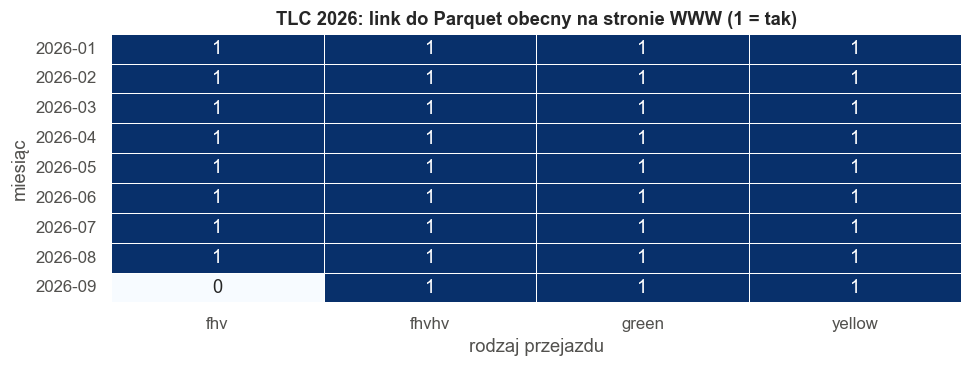

Dwa badane miesiące HVFHV obecne w katalogu WWW: True
Linki dla badanych miesięcy:


,month,file_url,source_page
229,2026-07,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...
230,2026-08,https://d37ci6vzurychx.cloudfront.net/trip-dat...,https://www.nyc.gov/site/tlc/about/tlc-trip-re...


In [30]:
if catalog_collection is not None and catalog_collection.count_documents({}):
    catalog_docs = list(catalog_collection.find({}, {"_id": 0, "scraped_at": 0}))
    cat_df = pd.DataFrame(catalog_docs)
    availability_by_year = pd.crosstab(cat_df["year"], cat_df["dataset"])
    display(availability_by_year.tail(12))

    year_current = 2026
    recent = cat_df[cat_df["year"] == year_current]
    matrix_2026 = pd.crosstab(recent["month"], recent["dataset"])
    fig, ax = plt.subplots(figsize=(9, max(3.5, len(matrix_2026) * 0.32)))
    sns.heatmap(matrix_2026, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                linewidths=0.5, linecolor="white")
    ax.set_title("TLC 2026: link do Parquet obecny na stronie WWW (1 = tak)")
    ax.set_xlabel("rodzaj przejazdu")
    ax.set_ylabel("miesiąc")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "01_katalog_tlc_2026.png", dpi=160)
    plt.show()

    expected_ids = {f"fhvhv:{m}" for m in MONTHS}
    found_ids = set(cat_df.apply(lambda r: f"{r['dataset']}:{r['month']}", axis=1))
    print("Dwa badane miesiące HVFHV obecne w katalogu WWW:", expected_ids <= found_ids)
    print("Linki dla badanych miesięcy:")
    display(cat_df[cat_df["month"].isin(MONTHS) & (cat_df["dataset"] == "fhvhv")][
        ["month", "file_url", "source_page"]])
else:
    print("[POMINIĘTO] Brak katalogu w Atlas — uruchom sekcje 9.1–9.2.")

## 10. Pipeline ETL: lokalne MongoDB -> agregaty dzienne -> Atlas

In [31]:
DAILY_PIPELINE = [
    {"$match": {"pickup_date": {"$gte": "2026-07-01", "$lte": "2026-08-31"}}},
    {"$group": {
        "_id": {"date": "$pickup_date", "provider": "$provider"},
        "trip_count": {"$sum": 1},
        "sum_base_fare": {"$sum": "$base_passenger_fare"},
        "sum_total_fare": {"$sum": "$total_fare"},
        "sum_driver_pay": {"$sum": "$driver_pay"},
        "sum_miles": {"$sum": "$trip_miles"},
        "sum_minutes": {"$sum": "$trip_minutes"},
        "sum_wait_minutes": {"$sum": "$wait_minutes"},
        "sum_tips": {"$sum": "$tips"},
        "trips_with_tip": {"$sum": {"$cond": [{"$gt": ["$tips", 0]}, 1, 0]}},
        "airport_trips": {"$sum": {"$cond": ["$is_airport_trip", 1, 0]}},
        "sum_congestion_fee": {"$sum": "$cbd_congestion_fee"},
        "trips_with_congestion_fee": {"$sum": {"$cond": [
            {"$gt": ["$cbd_congestion_fee", 0]}, 1, 0]}},
    }},
    {"$sort": {"_id.date": 1, "_id.provider": 1}},
]

def make_daily_documents(group_results, source_name="MongoDB local / analysis_sample (próba)"):
    processed = []
    for row in group_results:
        key = row["_id"]
        day, provider = key["date"], key["provider"]
        n = int(row["trip_count"])
        if n <= 0:
            continue
        values = {
            "_id": f"{day}:{provider}",
            "date": day, "provider": provider, "month": day[:7],
            "weekday": int(pd.Timestamp(day).dayofweek),
            "trip_count": n,
            "estimated_full_trip_count": float(n / EFFECTIVE_SOURCE_FRACTION),
            "mean_base_fare": float(row["sum_base_fare"] / n),
            "mean_total_fare": float(row["sum_total_fare"] / n),
            "mean_driver_pay": float(row["sum_driver_pay"] / n),
            "mean_miles": float(row["sum_miles"] / n),
            "mean_duration_minutes": float(row["sum_minutes"] / n),
            "mean_wait_minutes": float(row["sum_wait_minutes"] / n),
            "mean_tip_per_trip": float(row["sum_tips"] / n),
            "tip_rate_pct": float(100 * row["trips_with_tip"] / n),
            "airport_rate_pct": float(100 * row["airport_trips"] / n),
            "cbd_fee_rate_pct": float(100 * row["trips_with_congestion_fee"] / n),
            "sum_base_fare": float(row["sum_base_fare"]),
            "sum_total_fare": float(row["sum_total_fare"]),
            "sum_driver_pay": float(row["sum_driver_pay"]),
            "sum_tips": float(row["sum_tips"]),
            "source": source_name,
            "sample_fraction": float(EFFECTIVE_SOURCE_FRACTION),
            "analysis_sample_collection": analysis_name,
            "analysis_sample_count": ANALYSIS_COUNT,
            "local_source_count": SOURCE_TRIP_COUNT,
        }
        processed.append(values)
    return processed

local_daily_collection = db[DAILY_COLLECTION]
local_daily_collection.create_index([("date", 1), ("provider", 1)], unique=True)
local_daily_collection.create_index([("month", 1)])
local_daily_state = db["etl_pipeline_state"]
source_count_now = trips.estimated_document_count()
previous_state = local_daily_state.find_one({"_id": "daily_summary_v4_2_sample"})
rebuild_daily = (REFRESH_DAILY or local_daily_collection.count_documents({}) == 0
                 or previous_state is None
                 or previous_state.get("source_count") != source_count_now
                 or previous_state.get("analysis_collection") != analysis_name
                 or previous_state.get("analysis_count") != ANALYSIS_COUNT)

if rebuild_daily:
    print("[ETL] Przeliczam metryki dzienne na małej próbce analitycznej (nie na pełnej bazie).")
    pipeline_results = list(analysis_trips.aggregate(DAILY_PIPELINE, allowDiskUse=False, maxTimeMS=90_000))
    daily_documents = make_daily_documents(pipeline_results)
    if not daily_documents:
        raise RuntimeError("Brak wyników agregacji dziennej — sprawdź kolekcję z przejazdami.")
    local_etl_result = replace_records_idempotently(local_daily_collection, daily_documents)
    local_daily_state.replace_one({"_id": "daily_summary_v4_2_sample"}, {
        "_id": "daily_summary_v4_2_sample", "source_count": source_count_now,
        "analysis_collection": analysis_name, "analysis_count": ANALYSIS_COUNT,
        "date_range": MONTHS, "rows": len(daily_documents),
        "updated_at": datetime.now(timezone.utc),
    }, upsert=True)
    print("[ETL] Lokalna synchronizacja:", local_etl_result)
else:
    print("[ETL] Używam istniejących metryk z tej samej próbki analitycznej.")

daily_documents = list(local_daily_collection.find({}).sort("_id", 1))
print("Dokumenty dzienne:", len(daily_documents))
display(pd.DataFrame(daily_documents).drop(columns=["source"], errors="ignore").head(6))

[ETL] Używam istniejących metryk z tej samej próbki analitycznej.
Dokumenty dzienne: 124


,_id,date,provider,month,weekday,trip_count,estimated_full_trip_count,mean_base_fare,mean_total_fare,mean_driver_pay,mean_miles,mean_duration_minutes,mean_wait_minutes,mean_tip_per_trip,tip_rate_pct,airport_rate_pct,cbd_fee_rate_pct,sum_base_fare,sum_total_fare,sum_driver_pay,sum_tips,sample_fraction,analysis_sample_collection,analysis_sample_count,local_source_count
0,2026-07-01:Lyft,2026-07-01,Lyft,2026-07,2,228,"289,251.18",23.39,27.99,17.52,3.75,17.35,5.20,1.25,22.81,7.89,29.82,"5,333.45","6,380.75","3,994.48",284.31,0.00,analysis_sample_e034cb31e710_30000,30000,6376538
1,2026-07-01:Uber,2026-07-01,Uber,2026-07,2,499,"633,054.12",25.12,30.43,19.19,4.33,18.41,5.13,1.07,18.04,9.22,27.86,"12,533.56","15,183.98","9,576.58",535.12,0.00,analysis_sample_e034cb31e710_30000,30000,6376538
2,2026-07-02:Lyft,2026-07-02,Lyft,2026-07,3,218,"276,564.73",21.44,25.43,16.12,3.48,16.53,5.31,0.89,17.89,8.72,23.85,"4,674.87","5,543.75","3,514.41",193.69,0.00,analysis_sample_e034cb31e710_30000,30000,6376538
3,2026-07-02:Uber,2026-07-02,Uber,2026-07,3,534,"677,456.72",22.58,27.15,17.08,3.73,17.08,5.38,0.79,15.36,6.55,26.78,"12,056.46","14,497.52","9,121.03",422.85,0.00,analysis_sample_e034cb31e710_30000,30000,6376538
4,2026-07-03:Lyft,2026-07-03,Lyft,2026-07,4,256,"324,773.26",21.97,26.22,16.46,4.01,15.79,5.14,0.85,15.23,7.81,23.44,"5,624.08","6,713.30","4,214.67",216.45,0.00,analysis_sample_e034cb31e710_30000,30000,6376538
5,2026-07-03:Uber,2026-07-03,Uber,2026-07,4,548,"695,217.75",22.87,27.53,17.93,4.29,16.84,5.55,0.92,18.25,6.93,29.01,"12,530.81","15,084.46","9,827.31",502.96,0.00,analysis_sample_e034cb31e710_30000,30000,6376538


### 10.1. Synchronizacja agregatów do MongoDB Atlas i kontrola integralności

In [32]:
cloud_daily_collection = None
sync_first = sync_second = None
if atlas_enabled:
    cloud_daily_collection = atlas_db[DAILY_COLLECTION]
    cloud_daily_collection.create_index([("date", 1), ("provider", 1)], unique=True)
    cloud_daily_collection.create_index("month")
    cloud_before = cloud_daily_collection.count_documents({})
    sync_first = replace_records_idempotently(cloud_daily_collection, daily_documents)
    cloud_after_first = cloud_daily_collection.count_documents({})
    sync_second = replace_records_idempotently(cloud_daily_collection, daily_documents)
    cloud_after_second = cloud_daily_collection.count_documents({})
    assert cloud_after_first == cloud_after_second
    print("Atlas: przed=", cloud_before, "po 1. synchronizacji=", cloud_after_first,
          "po 2. synchronizacji=", cloud_after_second)
    print("Nowe dokumenty w 2. przebiegu:", sync_second["upserted"])
    assert sync_second["upserted"] == 0, "Drugi przebieg nie powinien tworzyć nowych rekordów."
    print("[TEST OK] Chmura nie duplikuje zagregowanych wyników.")
else:
    print("[POMINIĘTO] Synchronizacja wymaga MongoDB Atlas.")

Atlas: przed= 0 po 1. synchronizacji= 124 po 2. synchronizacji= 124
Nowe dokumenty w 2. przebiegu: 0
[TEST OK] Chmura nie duplikuje zagregowanych wyników.


In [33]:
KEY_METRICS = ("trip_count", "estimated_full_trip_count", "mean_base_fare",
               "mean_wait_minutes", "tip_rate_pct", "airport_rate_pct")

def stable_digest(documents):
    """Kontrolna suma wartości analitycznych: niezależna od kolejności i timestampów."""
    canonical = [{"_id": d["_id"], **{k: round(float(d[k]), 7) for k in KEY_METRICS}}
                 for d in documents]
    canonical.sort(key=lambda d: d["_id"])
    body = json.dumps(canonical, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(body.encode("utf-8")).hexdigest()

local_digest = stable_digest(daily_documents)
print("Lokalna suma kontrolna SHA256:", local_digest)
if cloud_daily_collection is not None:
    cloud_daily = list(cloud_daily_collection.find({}).sort("_id", 1))
    cloud_digest = stable_digest(cloud_daily)
    print("Cloud SHA256:", cloud_digest)
    assert len(cloud_daily) == len(daily_documents), "Różna liczba dokumentów na obu serwerach"
    assert cloud_digest == local_digest, "Rozbieżne wartości liczbowe pomiędzy bazami!"
    print("[TEST OK] Dwie różne instancje MongoDB przechowują spójne agregaty.")
else:
    print("[POMINIĘTO] Porównanie SHA256 możliwe dopiero po synchronizacji z Atlas.")

Lokalna suma kontrolna SHA256: 863acea5ddd32aa4393773e6ed85a6c7a3199ee1e072b4b691e82ffc3e8e8f0f
Cloud SHA256: 863acea5ddd32aa4393773e6ed85a6c7a3199ee1e072b4b691e82ffc3e8e8f0f
[TEST OK] Dwie różne instancje MongoDB przechowują spójne agregaty.


## 11. Analiza rozszerzona: dynamika rynku w układzie dziennym

In [34]:
daily_df = pd.DataFrame(daily_documents)
daily_df = daily_df[daily_df["provider"].isin(["Uber", "Lyft"])].copy()
daily_df["date_dt"] = pd.to_datetime(daily_df["date"])
daily_df["weekday_name"] = daily_df["date_dt"].dt.day_name()
daily_df["day_in_month"] = daily_df["date_dt"].dt.day
assert not daily_df.duplicated(["date", "provider"]).any(), "Powtórzone kombinacje (dzień, przewoźnik)"
assert (daily_df["trip_count"] > 0).all()
assert daily_df["mean_base_fare"].notna().all()
print(f"Dni: {daily_df['date'].nunique()} | obserwacje dzienne: {len(daily_df)}")

def weighted_mean(frame, value, weight="trip_count"):
    return float(np.average(frame[value], weights=frame[weight]))

summary_daily = (daily_df.groupby(["month", "provider"], as_index=False)
    .apply(lambda g: pd.Series({
        "dni": g["date"].nunique(),
        "przejazdy_probka": int(g["trip_count"].sum()),
        "przejazdy_oszacowane": float(g["estimated_full_trip_count"].sum()),
        "srednia_oplata_usd": weighted_mean(g, "mean_base_fare"),
        "srednie_oczekiwanie_min": weighted_mean(g, "mean_wait_minutes"),
        "odsetek_napiwkow_pct": weighted_mean(g, "tip_rate_pct"),
        "odsetek_lotniskowych_pct": weighted_mean(g, "airport_rate_pct"),
    }), include_groups=False).reset_index(drop=True))
display(summary_daily)

Dni: 62 | obserwacje dzienne: 124


,month,provider,dni,przejazdy_probka,przejazdy_oszacowane,srednia_oplata_usd,srednie_oczekiwanie_min,odsetek_napiwkow_pct,odsetek_lotniskowych_pct
0,2026-07,Lyft,31.00,"4,627.00","5,870,022.89",24.02,5.21,21.44,7.89
1,2026-07,Uber,31.00,"12,425.00","15,762,920.77",25.18,5.50,18.29,8.23
2,2026-08,Lyft,31.00,"3,583.00","4,545,556.95",23.29,5.08,22.55,7.59
3,2026-08,Uber,31.00,"9,365.00","11,880,865.43",24.49,5.44,18.11,8.34


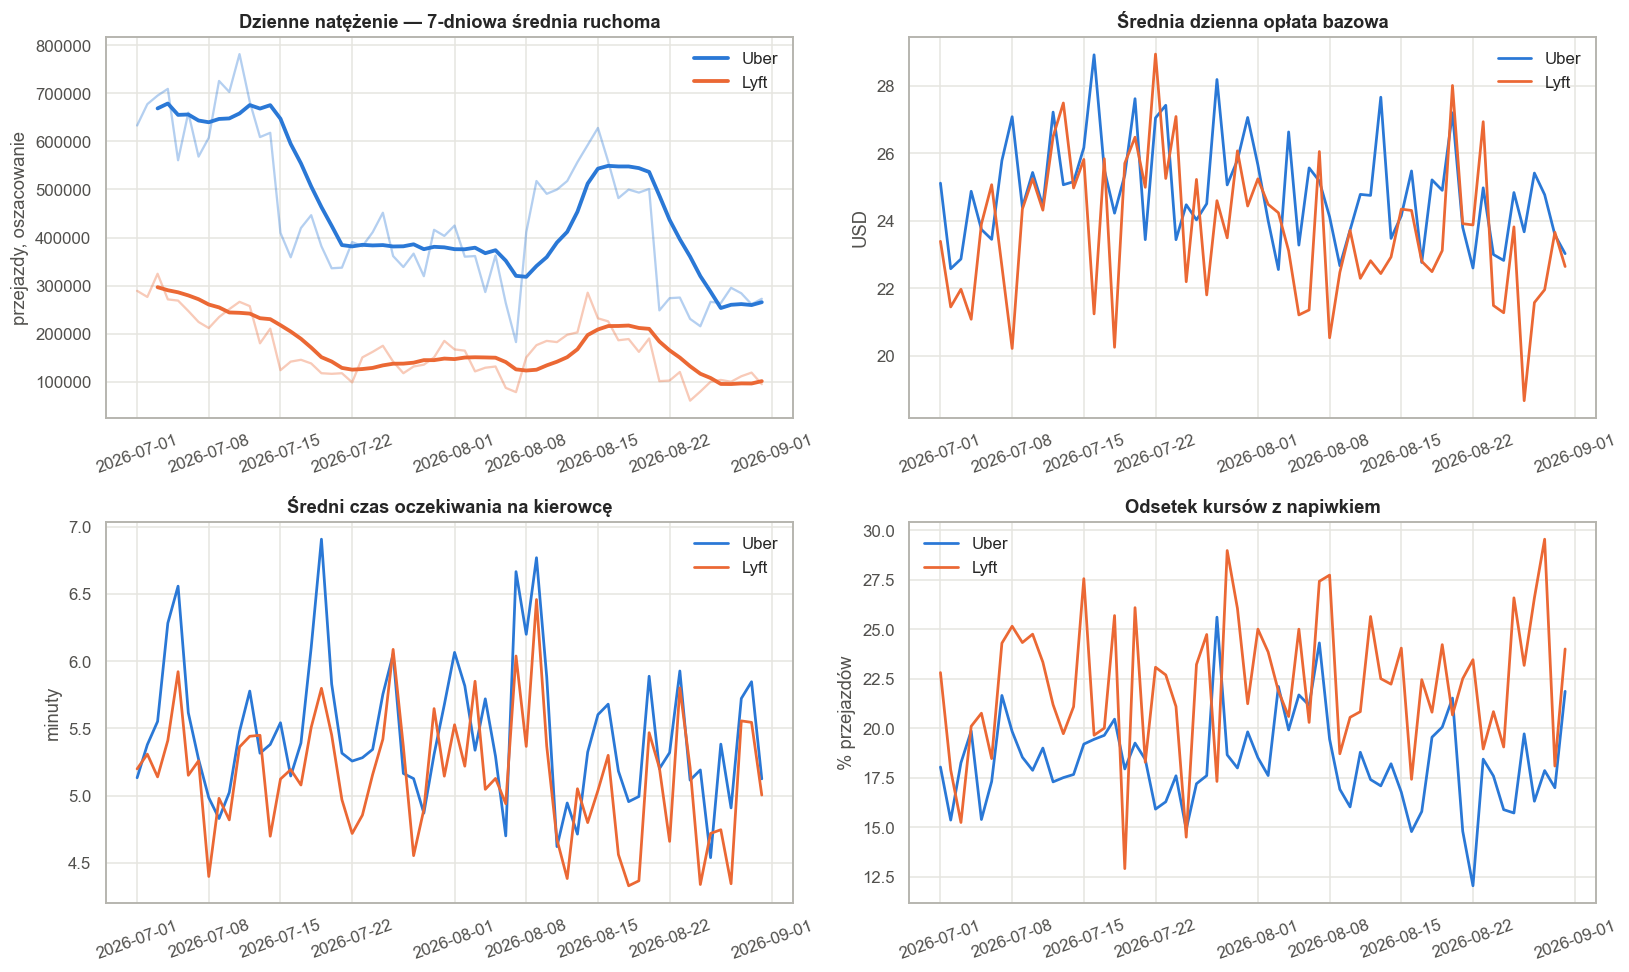

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for company in ["Uber", "Lyft"]:
    d = daily_df[daily_df["provider"] == company].sort_values("date_dt")
    c = PROVIDER_COLORS[company]
    axes[0, 0].plot(d["date_dt"], d["estimated_full_trip_count"], alpha=0.35, color=c)
    axes[0, 0].plot(d["date_dt"], d["estimated_full_trip_count"].rolling(7, min_periods=3).mean(),
                    label=company, linewidth=2.5, color=c)
    axes[0, 1].plot(d["date_dt"], d["mean_base_fare"], label=company, color=c, linewidth=1.8)
    axes[1, 0].plot(d["date_dt"], d["mean_wait_minutes"], label=company, color=c, linewidth=1.8)
    axes[1, 1].plot(d["date_dt"], d["tip_rate_pct"], label=company, color=c, linewidth=1.8)

for ax, title, ylabel in [
    (axes[0, 0], "Dzienne natężenie — 7-dniowa średnia ruchoma", "przejazdy, oszacowanie"),
    (axes[0, 1], "Średnia dzienna opłata bazowa", "USD"),
    (axes[1, 0], "Średni czas oczekiwania na kierowcę", "minuty"),
    (axes[1, 1], "Odsetek kursów z napiwkiem", "% przejazdów"),
]:
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_trendy_dzienne.png", dpi=160)
plt.show()

### 11.1. Udział przewoźników - zmienność z dnia na dzień

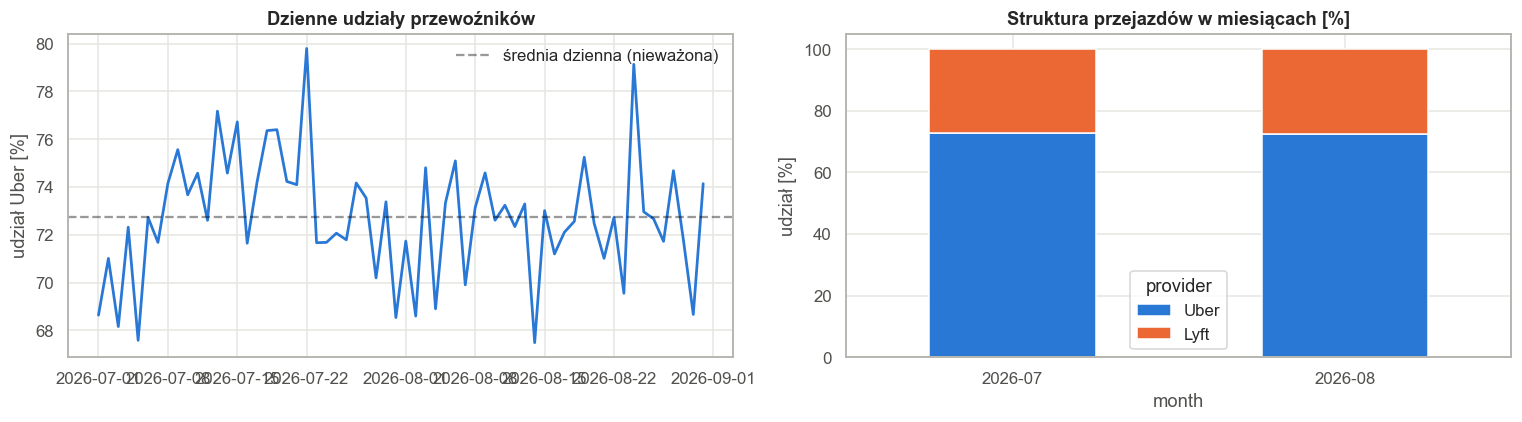

Min/max dzienny udział Uber: 67.49% / 79.79%


provider,Uber,Lyft
month,,
2026-07,72.87,27.13
2026-08,72.33,27.67


In [36]:
market = daily_df.pivot(index="date_dt", columns="provider", values="trip_count").fillna(0)
market["Uber_share_pct"] = 100 * market["Uber"] / (market["Uber"] + market["Lyft"])
market["month"] = market.index.strftime("%Y-%m")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(market.index, market["Uber_share_pct"], color=PROVIDER_COLORS["Uber"], lw=1.8)
axes[0].axhline(market["Uber_share_pct"].mean(), color="black", alpha=0.4,
                ls="--", label="średnia dzienna (nieważona)")
axes[0].set_ylabel("udział Uber [%]")
axes[0].set_title("Dzienne udziały przewoźników")
axes[0].legend(frameon=False)
monthly_shares = market.groupby("month").agg({"Uber": "sum", "Lyft": "sum"})
monthly_shares = monthly_shares.div(monthly_shares.sum(axis=1), axis=0) * 100
monthly_shares.plot(kind="bar", stacked=True, ax=axes[1],
                    color=[PROVIDER_COLORS["Uber"], PROVIDER_COLORS["Lyft"]])
axes[1].set_title("Struktura przejazdów w miesiącach [%]")
axes[1].set_ylabel("udział [%]")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_udzial_rynkowy.png", dpi=160)
plt.show()
print("Min/max dzienny udział Uber:",
      f"{market['Uber_share_pct'].min():.2f}% / {market['Uber_share_pct'].max():.2f}%")
display(monthly_shares)

## 12. Wnioskowanie statystyczne na poziomie dni (uzupełnienie analiz 3.0)

- **Test Wilcoxona**: sparowane dni, hipoteza o symetrycznym rozkładzie różnic i medianie równej zero; mała wartość p nie mówi o skali różnicy.
- **Bootstrap po dniach**: przedział ufności średniej *dziennej różnicy* (nie średniej różnicy na kurs); zależności czasowe między dniami mogą zawyżać precyzję, więc wynik traktujemy jako przybliżenie eksploracyjne.
- **Efekt praktyczny**: różnica w USD lub minutach, a nie samo p-value.

In [37]:
def paired_daily_comparison(df, metric, label, bootstrap_reps=3_000, seed=42):
    paired = df.pivot_table(index="date_dt", columns="provider", values=metric, aggfunc="first")
    paired = paired[["Uber", "Lyft"]].dropna()
    differences = (paired["Uber"] - paired["Lyft"]).to_numpy(dtype=float)
    n = len(differences)
    if n < 10:
        raise ValueError(f"Za mało sparowanych dni dla {label}: {n}")
    if np.all(differences == 0):
        p = 1.0
    else:
        p = float(stats.wilcoxon(differences, alternative="two-sided").pvalue)
    rng = np.random.default_rng(seed)
    boot = rng.choice(differences, size=(bootstrap_reps, n), replace=True).mean(axis=1)
    return {
        "metryka": label, "dni": n,
        "srednia_roznica_Uber_minus_Lyft": float(differences.mean()),
        "mediana_roznicy": float(np.median(differences)),
        "bootstrap_ci_low": float(np.percentile(boot, 2.5)),
        "bootstrap_ci_high": float(np.percentile(boot, 97.5)),
        "wilcoxon_p": p,
    }

metrics_to_compare = [
    ("mean_base_fare", "Średnia opłata bazowa [USD]"),
    ("mean_wait_minutes", "Czas oczekiwania [min]"),
    ("tip_rate_pct", "Odsetek kursów z napiwkiem [pp]"),
    ("mean_miles", "Dystans [mile]"),
]
paired_table = pd.DataFrame([
    paired_daily_comparison(daily_df, metric, label)
    for metric, label in metrics_to_compare
])
display(paired_table)
paired_table.to_csv(OUTPUT_DIR / "testy_sparowane_dni.csv", index=False)

,metryka,dni,srednia_roznica_Uber_minus_Lyft,mediana_roznicy,bootstrap_ci_low,bootstrap_ci_high,wilcoxon_p
0,Średnia opłata bazowa [USD],62,1.16,0.81,0.64,1.73,0.00
1,Czas oczekiwania [min],62,0.32,0.38,0.23,0.40,0.00
2,Odsetek kursów z napiwkiem [pp],62,-3.91,-3.70,-4.86,-2.96,0.00
3,Dystans [mile],62,0.29,0.27,0.18,0.41,0.00


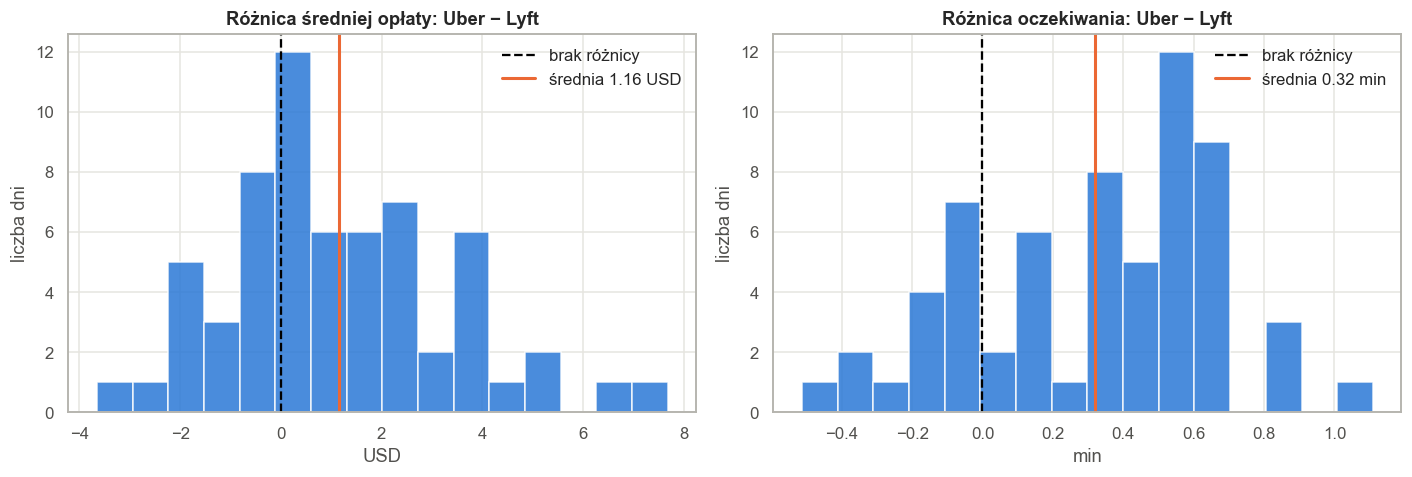

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title, unit in [
    (axes[0], "mean_base_fare", "Różnica średniej opłaty: Uber − Lyft", "USD"),
    (axes[1], "mean_wait_minutes", "Różnica oczekiwania: Uber − Lyft", "min"),
]:
    p = daily_df.pivot(index="date_dt", columns="provider", values=metric).dropna()
    diff = p["Uber"] - p["Lyft"]
    ax.hist(diff, bins=16, color=SERIES[0], edgecolor="white", alpha=0.85)
    ax.axvline(0, color="black", ls="--", label="brak różnicy")
    ax.axvline(diff.mean(), color=SERIES[1], lw=2, label=f"średnia {diff.mean():.2f} {unit}")
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.set_ylabel("liczba dni")
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_roznice_sparowane.png", dpi=160)
plt.show()

### 12.1. Czy dni tygodnia różnią się popytem?

Poniedziałek i sobota nie powinny być porównywane bez uwzględnienia liczby wystąpień każdego dnia w badanym okresie. Dlatego pokazujemy **średnią liczbę przejazdów na jeden występujący dzień tygodnia**.

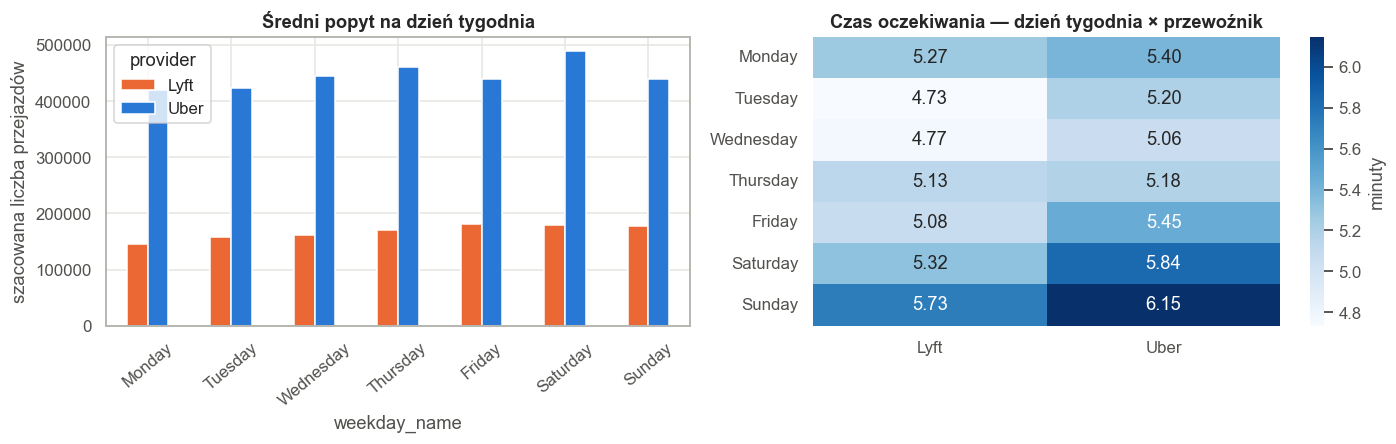

,weekday_name,provider,dzienna_srednia_przejazdow,sredni_odsetek_napiwkow,sredni_czas_oczekiwania
0,Friday,Lyft,"181,698.23",22.34,5.08
2,Monday,Lyft,"145,753.28",22.08,5.27
4,Saturday,Lyft,"179,583.82",23.71,5.32
6,Sunday,Lyft,"177,046.53",19.45,5.73
8,Thursday,Lyft,"171,126.19",21.91,5.13
10,Tuesday,Lyft,"158,263.53",20.28,4.73
12,Wednesday,Lyft,"161,399.90",25.44,4.77
1,Friday,Uber,"439,092.32",18.53,5.45
3,Monday,Uber,"420,203.59",18.33,5.40
5,Saturday,Uber,"490,120.06",17.65,5.84


In [39]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
week_profile = (daily_df.groupby(["weekday_name", "provider"], as_index=False)
    .agg(dzienna_srednia_przejazdow=("estimated_full_trip_count", "mean"),
         sredni_odsetek_napiwkow=("tip_rate_pct", "mean"),
         sredni_czas_oczekiwania=("mean_wait_minutes", "mean")))
heat_week = week_profile.pivot(index="weekday_name", columns="provider",
                              values="dzienna_srednia_przejazdow").reindex(dow_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
heat_week.plot(kind="bar", ax=axes[0],
               color=[PROVIDER_COLORS["Lyft"], PROVIDER_COLORS["Uber"]])
axes[0].set_title("Średni popyt na dzień tygodnia")
axes[0].set_ylabel("szacowana liczba przejazdów")
axes[0].tick_params(axis="x", rotation=40)
heat_wait = week_profile.pivot(index="weekday_name", columns="provider",
                              values="sredni_czas_oczekiwania").reindex(dow_order)
sns.heatmap(heat_wait, cmap="Blues", annot=True, fmt=".2f", ax=axes[1],
            cbar_kws={"label": "minuty"})
axes[1].set_title("Czas oczekiwania — dzień tygodnia × przewoźnik")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_dzien_tygodnia.png", dpi=160)
plt.show()
display(week_profile.sort_values(["provider", "weekday_name"]))

## 13. Wykrywanie dni nietypowych z korektą na dzień tygodnia

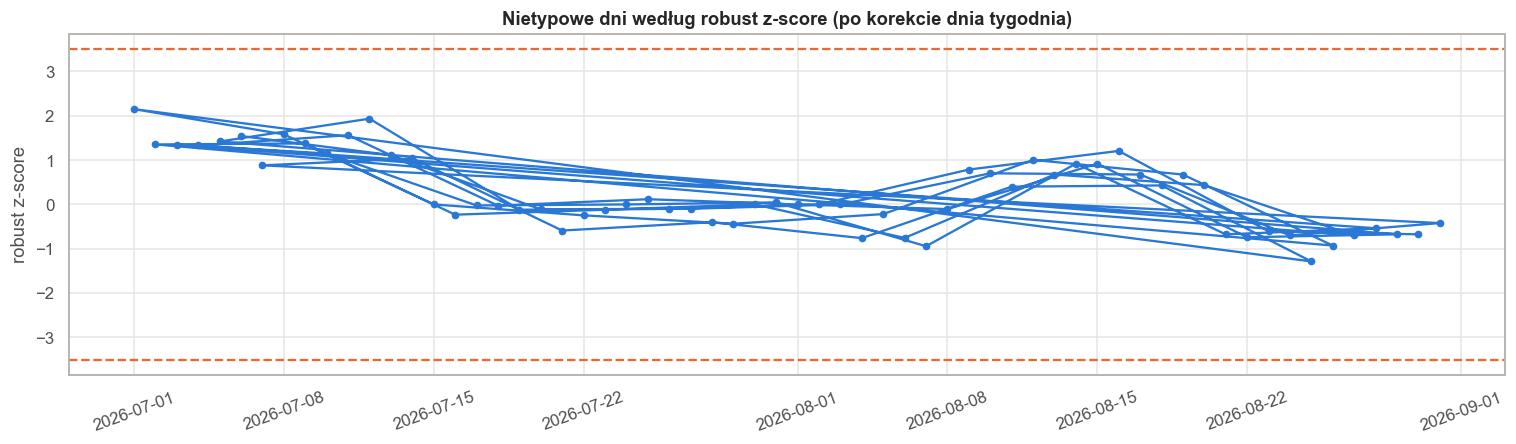

Dni oznaczone jako nietypowe: 0


,date_dt,estimated_trips,weekday,robust_z


In [40]:
traffic_days = (daily_df.groupby("date_dt", as_index=False)
                .agg(estimated_trips=("estimated_full_trip_count", "sum")))
traffic_days["weekday"] = traffic_days["date_dt"].dt.dayofweek

def robust_weekday_score(frame):
    x = frame["estimated_trips"]
    med = x.median()
    mad = np.median(np.abs(x - med))
    out = frame.copy()
    out["normal_for_weekday"] = med
    out["robust_z"] = 0.6745 * (x - med) / mad if mad > 1e-9 else 0.0
    return out

traffic_days = pd.concat([robust_weekday_score(g) for _, g in
                          traffic_days.groupby("weekday")], ignore_index=True)
traffic_days["outlier"] = traffic_days["robust_z"].abs() > 3.5
outliers = traffic_days[traffic_days["outlier"]].sort_values("robust_z")
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(traffic_days["date_dt"], traffic_days["robust_z"], marker="o",
        ms=4, color=SERIES[0], label="odchylenie od typowego dnia tygodnia")
ax.axhline(3.5, color=SERIES[1], ls="--")
ax.axhline(-3.5, color=SERIES[1], ls="--")
ax.set_title("Nietypowe dni według robust z-score (po korekcie dnia tygodnia)")
ax.set_ylabel("robust z-score")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_anomalie_dzienne.png", dpi=160)
plt.show()
print("Dni oznaczone jako nietypowe:", len(outliers))
display(outliers[["date_dt", "estimated_trips", "weekday", "robust_z"]])

## 14. Testy końcowe: idempotencja, spójność, pochodzenie, wielkość

Podstawowy dowód idempotencji jest **operacyjny**: dwukrotny `upsert` rzeczywiście wykonuje operacje na serwerze, a liczba rekordów i sumy kontrolne pozostają stałe. Poniższy lokalny test wykorzystuje dwa syntetyczne rekordy w **osobnej kolekcji demonstracyjnej** - bez ingerencji w 5+ GiB właściwych danych.

In [42]:
demo_collection = db["etl_idempotence_demo"]
demo_collection.create_index([("source", 1), ("event_id", 1)], unique=True)
synthetic_records = [
    {"_id": "demo:A", "source": "test", "event_id": "A", "value": 11},
    {"_id": "demo:B", "source": "test", "event_id": "B", "value": 22},
]
count_before_demo = demo_collection.count_documents({"source": "test"})
first_demo = replace_records_idempotently(demo_collection, synthetic_records)
count_after_first_demo = demo_collection.count_documents({"source": "test"})
second_demo = replace_records_idempotently(demo_collection, synthetic_records)
count_after_second_demo = demo_collection.count_documents({"source": "test"})
assert count_after_first_demo == 2
assert count_after_second_demo == 2
assert second_demo["upserted"] == 0

print("Lokalna demonstracja:")
print({"przed": count_before_demo, "po_1": count_after_first_demo,
       "po_2": count_after_second_demo, "upserted_2": second_demo["upserted"]})
print("[TEST OK] Lokalna baza MongoDB odporna na ponowny import tej samej partii.")

Lokalna demonstracja:
{'przed': 2, 'po_1': 2, 'po_2': 2, 'upserted_2': 0}
[TEST OK] Lokalna baza MongoDB odporna na ponowny import tej samej partii.


In [43]:
checks = [
    ("Lokalne MongoDB odpowiada", local_ping.get("ok") == 1),
    ("Źródło zawiera >= 5 mld bajtów po dekompresji Parquet", parquet_uncompressed >= 5_000_000_000),
    ("Przechowywane dokumenty BSON >= 5 GiB", mongo_coll["size"] >= 5 * GIB),
    ("Lokalne rekordy dzienne mają unikatowe _id", len(daily_documents) == len({r["_id"] for r in daily_documents})),
    ("Test lokalnego ponownego importu", count_after_second_demo == count_after_first_demo),
    ("Połączenie z Atlas działa", atlas_enabled),
    ("Scraping wykonany na żywej stronie WWW", bool(scraped_rows)),
    ("Katalog w Atlas istnieje", (catalog_collection is not None and catalog_collection.count_documents({}) > 0)),
    ("Sync agregatów do Atlas wykonany", (cloud_daily_collection is not None and cloud_daily_collection.count_documents({}) > 0)),
    ("Sumy kontrolne lokal/chmura zgodne", bool(cloud_digest == local_digest)
     if cloud_daily_collection is not None else False),
]
checks_df = pd.DataFrame(checks, columns=["wymóg_kontrola", "zaliczony"])
checks_df["status"] = checks_df["zaliczony"].map({True: "OK", False: "BRAK / SPRAWDŹ"})
display(checks_df[["wymóg_kontrola", "status"]])
print(f"Zrealizowano w tym środowisku: {checks_df['zaliczony'].sum()} / {len(checks_df)} kontroli")
checks_df.to_csv(OUTPUT_DIR / "kontrola_wymagan.csv", index=False)

,wymóg_kontrola,status
0,Lokalne MongoDB odpowiada,OK
1,Źródło zawiera >= 5 mld bajtów po dekompresji ...,BRAK / SPRAWDŹ
2,Przechowywane dokumenty BSON >= 5 GiB,OK
3,Lokalne rekordy dzienne mają unikatowe _id,OK
4,Test lokalnego ponownego importu,OK
5,Połączenie z Atlas działa,OK
6,Scraping wykonany na żywej stronie WWW,OK
7,Katalog w Atlas istnieje,OK
8,Sync agregatów do Atlas wykonany,OK
9,Sumy kontrolne lokal/chmura zgodne,OK


Zrealizowano w tym środowisku: 9 / 10 kontroli


### 15.1. Eksport wyników i danych

In [44]:
%pip install tabulate

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
summary_daily.to_csv(OUTPUT_DIR / "agregaty_miesieczne.csv", index=False)
daily_df.drop(columns=["_id"], errors="ignore").to_csv(
    OUTPUT_DIR / "agregaty_dzienne.csv", index=False
)
market.to_csv(OUTPUT_DIR / "udzial_rynkowy_dziennie.csv")
scale_audit.to_csv(OUTPUT_DIR / "audyt_rozmiaru_danych.csv", index=False)
if atlas_enabled and catalog_collection is not None and catalog_collection.count_documents({}):
    pd.DataFrame(list(catalog_collection.find({}, {"_id": 0}))).to_csv(
        OUTPUT_DIR / "katalog_tlc_scraping.csv", index=False
    )

lines = [
    "# Raport automatyczny Big Data — NYC TLC (rozszerzenie na 4.0)",
    "", f"Data raportu (UTC): {datetime.now(timezone.utc).isoformat()}",
    "", "## Architektura", "MongoDB lokalne: przejazdy i agregaty dzienne.",
    "MongoDB Atlas Free: katalog HTML TLC oraz zsynchronizowane agregaty (jeśli podłączono).",
    "", "## Skala", f"Wiersze surowe: {merged.metadata.num_rows:,}",
    f"Nieskompresowane Parquet: {parquet_uncompressed / GIB:.2f} GiB",
    f"Lokalne dokumenty MongoDB: {mongo_coll['count']:,}",
    f"MongoDB BSON: {mongo_coll['size'] / GIB:.2f} GiB",
    "", "## Kontrole (rzeczywiście wykonane w tym środowisku)",
]
lines += [f"- {row['wymóg_kontrola']}: {row['status']}" for _, row in checks_df.iterrows()]
lines += ["", "## Statystyka dzienna (bez fikcyjnych wyników)",
          paired_table.to_markdown(index=False, floatfmt=".4f"),
          "", "## Ograniczenia",
          "- Przejazdy w MongoDB to losowa próbka po odrzuceniu błędnych rekordów.",
          f"- Statystyki i ETL obliczono na dalszej próbce analitycznej {ANALYSIS_COUNT:,} z {SOURCE_TRIP_COUNT:,} dokumentów MongoDB.",
          "- Dzienne i globalne liczebności dla źródła to EKSTRAPOLACJE, nie dokładne pomiary.",
          "- Dane z web scrapingu to metadane linków, nie dane samych przejazdów.",
          "- Darmowy Atlas nie może przechowywać wszystkich 5+ GiB.",
          "- Zapisane wykresy w oryginalnej części notebooka są historyczne."]
(OUTPUT_DIR / "SPRAWOZDANIE_AUTOMATYCZNE.md").write_text("\n".join(lines), encoding="utf-8")
print("Wyniki zapisano w katalogu:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print("•", p.name, f"({p.stat().st_size / 1024:.1f} KiB)")

Wyniki zapisano w katalogu: C:\Users\mpila\Desktop\bigdata\bigdata_nyc_4_0\reports
• 01_katalog_tlc_2026.png (50.6 KiB)
• 02_trendy_dzienne.png (479.5 KiB)
• 03_udzial_rynkowy.png (114.0 KiB)
• 04_roznice_sparowane.png (54.8 KiB)
• 05_dzien_tygodnia.png (128.1 KiB)
• 06_anomalie_dzienne.png (122.1 KiB)
• agregaty_dzienne.csv (48.0 KiB)
• agregaty_miesieczne.csv (0.6 KiB)
• audyt_rozmiaru_danych.csv (0.3 KiB)
• katalog_tlc_scraping.csv (147.2 KiB)
• kontrola_wymagan.csv (0.5 KiB)
• SPRAWOZDANIE_AUTOMATYCZNE.md (2.4 KiB)
• testy_sparowane_dni.csv (0.6 KiB)
• udzial_rynkowy_dziennie.csv (2.8 KiB)
